# SLR09 — Inferensi, Review Final, dan Evaluasi v0.3

Workflow: **periksa asal notebook → jalankan pemeriksaan kode → replay prediksi tersimpan → evaluasi label final → lihat confusion matrix → opsional inferensi ulang dari Drive di Colab → ekspor bukti**.

Notebook ini memuat **kode lengkap** runtime 0.2.0, filter normalisasi, evaluasi, pemeriksaan, dan ekspor. Semua file Python dapat dibaca pada cell sumber dan di folder `code/` pada paket ZIP. Data replay berasal dari inferensi nyata 16 Oktober 2026, bukan prediksi buatan.

**Status bawaan:** `RUN_NEURAL_INFERENCE = False`. Run All memeriksa kode dan memproses ulang output neural yang sudah tersimpan. Untuk menjalankan jaringan neural lagi di Colab, ubah menjadi `True`, isi `DRIVE_FOLDER`, lalu Run All. Mode replay tidak memerlukan model ZIP atau koneksi Drive. Mode neural memerlukan tiga ZIP yang telah diaudit dan dapat lebih lama pada CPU.

| Bagian siklus model | Bukti yang tersedia |
|---|---|
| Pengolahan data, pelatihan SENA, evaluasi, confusion matrix, ekspor model | Notebook asli `TanggapMakna_V3A_EventClassifier.ipynb` di folder `historical/`; kode tersedia, cell output tidak tersimpan pada berkas yang diterima |
| Pelatihan asli NARA | Notebook belum tersedia; hyperparameter dan alignment pelatihan tidak dapat dipastikan dari notebook asli |
| Fusion lama dan evaluasi blind lama | Dua notebook asli di `historical/`, sebagai riwayat arsitektur GEMASTIK; bukan aturan aktif SILAR |
| Inferensi SENA/NARA, pemetaan A4.22, review final, metrik dan bukti SLR09 | Notebook aktif ini; mode dan status eksekusi dicatat pada setiap hasil |

**Batas interpretasi:** kategori berasal dari SENA; NON_EVENT tetap memblokir konfirmasi. Human Verification tetap diperlukan. Pilihan A INFORMATION-ARG sebagai usulan impacts dipertahankan, dengan filter lokasi sederhana. Waktu fallback yang disangkal eksplisit dibuang. Filter tidak mengisi field yang hilang dan bukan pendeteksi semantik umum. Model, PRD, UI, backend, dan skema database tidak diubah.

Sebanyak 71 label SENA direview setelah kasus berbeda dari label sumber diketahui. Metrik campuran memakai 71 label final tersebut dan 552 label sumber yang belum direview. Sebanyak 11 nilai NARA pada 8 narasi dipilih karena bermasalah. Hasil ini merupakan analisis retrospektif dan uji regresi; bukan blind test independen atau accuracy NARA keseluruhan. ID validation historis SENA belum terbukti. Threshold produksi tetap belum dipilih.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.util
import json
import os
import shutil
import subprocess
import sys
import zipfile

# cpu: jalur tanpa GPU; dapat lebih lambat. CPU Colab bukan bukti kapasitas VM.
# cuda: lebih cepat jika GPU aktif; hasil performanya tidak mewakili VM tanpa GPU.
RUN_NEURAL_INFERENCE = False  # True: inferensi ulang nyata dari Drive di Google Colab.
RUNTIME_DEVICE = "cpu"
CPU_THREADS = None  # Opsional; isi integer positif hanya bila ingin mengatur thread.
# Contoh folder: buat My Drive/SILAR_SLR09 lalu letakkan tiga ZIP asli di sana.
# Ganti DRIVE_FOLDER jika file Anda disimpan di folder lain.
DRIVE_MOUNT_POINT = Path("/content/drive")
DRIVE_FOLDER = DRIVE_MOUNT_POINT / "MyDrive" / "SILAR_SLR09"
# Cache ZIP lokal dipakai ulang hanya jika hash cocok; tetap terhapus jika VM direset.
INPUT_DIRECTORY = Path("/content/silar_slr09_zip_cache")

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
WORK_ROOT = Path.cwd() / "slr09_runtime" / RUN_ID
CODE_DIR = WORK_ROOT / "code"
RESULT_DIR = WORK_ROOT / "results"
ASSET_DIR = WORK_ROOT / "assets"
CODE_DIR.mkdir(parents=True, exist_ok=False)
RESULT_DIR.mkdir(parents=True, exist_ok=False)
SETUP_OK = False
INPUT_OK = False
RUN_STATE = {"run_id": RUN_ID, "status": "PREPARING", "steps": [],
             "production_threshold_selected": False, "training_executed": False,
             "new_neural_inference_executed": False, "replay_executed": False,
             "input_source": "EMBEDDED_PRIOR_RUNTIME_FOR_REPLAY; GOOGLE_DRIVE_COPY_IF_NEURAL_ENABLED", "notebook_revision": "0.3"}

def save_state():
    (RESULT_DIR / "notebook_run_state.json").write_text(
        json.dumps(RUN_STATE, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

save_state()
print("Run:", RUN_ID, "Device:", RUNTIME_DEVICE)

BASELINE_DIR = WORK_ROOT / "baseline_evidence"
BASELINE_DIR.mkdir(parents=True, exist_ok=False)
REPLAY_OK = False


Run: 20261017T120856_319468Z Device: cpu


## Sumber lengkap dan pemeriksaan hash

Cell berikut menulis semua sumber ke folder run yang baru. Kode asli helper Fusion untuk span/guard tetap identik; filter review diterapkan pada lapisan adapter. JSON referensi final berisi 71 keputusan SENA dan 11 nilai NARA dari workbook review Anda, beserta hash sumbernya. Data baseline dikemas terkompresi untuk replay; kode Python tidak disembunyikan di dalam data tersebut.


In [2]:
EXPECTED_CODE_SHA256 = {'asset_lock.json': '31fbe639ea58f7c235ff0a8243704a09ad92f032390444aa961db6d4569b2db7', 'legacy_postprocessing.py': '06275b3aa338718689fba66984626754e6b34739156f65e378ceaad4b06bfa9f', 'legacy_source_trace.json': '09db4fc8d7dbb73e1a2ea584c6f674eda2199c86c7b722c31b8987a432574ce1', 'requirements-runtime.txt': 'b18016a51c23428d97878774970d5fe2fbcc43fe0afa555a493efaf0a3e899d7', 'reviewed_references.json': '64612d398b7fa8cf4d1f3ddfb0ef86b6cbd49904553df9dae807f42988665868', 'silar_ai_adapter.py': '9c34e9f6220a82882b8de74436b1dd75db7d23c9c263312d6beded3e575c9137', 'silar_postprocessing.py': '38aaf3d18274a79bf056aac3591e922ae015f2d403a3eb0ed9a71060c1197abd', 'slr09_calibration.py': '0589673f151a91ae34bea1d9e1c0dd5f8b0a464c487bdd09e3bafb9c28750693', 'slr09_plots.py': 'fe157120ce7e2e7f4f7e77bdc356c95871eb58e90a28da6ad89f138bc580114f', 'slr09_review_evaluation.py': 'eb9b9a33836881611b73f7990a9b7f194c603ceaed996432f4f53d5d6a7b3b44', 'slr09_runtime.py': 'dfe7827c063f613fa044cabcb74e827bf9e67c1e07dbcefd32855f22e024c48e', 'smoke_cases.jsonl': '1e3c1ca0c407121b454ccbae2b76436c1641dbe1f4cf2279cd203a1065133633', 'synthetic_fixture.py': '226a52379b37f89f86ae4981fe73d4d9347911d065b99ffdd7faceb9bcc9ac7f', 'test_silar_ai_adapter.py': 'd0b8490c581ee4c615ac421655cdb0381937a65dfb31b4c60e58454004009fee', 'test_silar_postprocessing.py': 'c02a69783feb00e7510702997404653d45c4fc034a1423ca0aad249c584954a8', 'test_slr09_review_evaluation.py': '6f044c893d120c206ab7d55ae0556e5962564eaa77d9e79f23e76d2af82f00db', 'test_slr09_runtime.py': 'd2bc503df24c7fcf21dc0169bf5e9655ecc41b6774fe33a532f95d24abb4a558'}
EMBEDDED_FILES = {}

def stage_text(filename, source):
    encoded = source.encode("utf-8")
    if hashlib.sha256(encoded).hexdigest() != EXPECTED_CODE_SHA256[filename]:
        raise ValueError("Hash sumber tidak cocok: " + filename)
    (CODE_DIR / filename).write_bytes(encoded)
    EMBEDDED_FILES[filename] = source


In [3]:
# Sumber lengkap: asset_lock.json
stage_text('asset_lock.json', r'''{
  "package_version": "0.2.0",
  "models": {
    "sena": {
      "model_id": "SILAR_SENA_v1",
      "archive_sha256": "e4af9d1e09023bcfb29670f2ff93d9aa477e8af6990d1ad21192d50486de57f6",
      "files": {
        "config.json": "b05589deb775fe55afee6300ed91b7a2cfd9a60917b678bfc55e826f7e6840e4",
        "tokenizer.json": "9fe32d346105f405394d2ba3f4c15df117127584e6042336956f15e1357857d3",
        "tokenizer_config.json": "9f0c2c65a70ea18113ffa2e717103e7210ea826e7acc3442b69b346686b55a48",
        "model.safetensors": "ae7ceb9959b7f0f3c55a6babd2cf73759a1d9458daadb654ca2fb68ca25cc4dc"
      },
      "labels": [
        "FLOOD",
        "EARTHQUAKE",
        "FIRE",
        "ACCIDENT",
        "NON_EVENT"
      ]
    },
    "nara": {
      "model_id": "SILAR_NARA_v1",
      "archive_sha256": "9c670e099481057f307b34fd2ea0fd5a65d8df38796cd82fc45e7ee29272341f",
      "files": {
        "config.json": "7b31561467ebcc180a4ab13a249c8cebb5462672670b6371ca7fbbad0d408293",
        "tokenizer.json": "9fe770007d1727a8cacfec0b467e2b6d6f60d7ff93f3b0be692d63c62ccc856d",
        "tokenizer_config.json": "9f0c2c65a70ea18113ffa2e717103e7210ea826e7acc3442b69b346686b55a48",
        "model.safetensors": "f80a007e2e3a6ce3d444899656284b906283bc15a927888539aa9da1b7dbc3d4"
      },
      "labels": [
        "O",
        "ACCIDENT-EVENT",
        "AFFECTEDOBJECTS-ARG",
        "DEATHVICTIM-ARG",
        "EARTHQUAKE-EVENT",
        "FALSE-EVENT",
        "FIRE-EVENT",
        "FLOOD-EVENT",
        "INFORMATION-ARG",
        "OFFICER-ARG",
        "PLACE-ARG",
        "REASON-ARG",
        "STREET-ARG",
        "TIME-ARG",
        "WOUNDVICTIM-ARG"
      ]
    }
  },
  "source_notebooks": {
    "legacy_fusion_sha256": "92b4c6b9bcd510148d3534657caed3acde6322e62d75eba0f9ec3150e859b525",
    "sena_training_sha256": "70aceec827004bf603f4e41032860bb8ca486c7f26efd228863472bec768c380"
  },
  "dataset": {
    "archive_sha256": "3e22f54044e7b44f49a243aeb3e6fdad3dc2ce0d000ce8a0fd5a33f7d9c56cbf",
    "csv_sha256": "14ff9121e37cdaed2a0b8f35e2131da4c710daebf2cad0781fdbbdfdad00c211"
  }
}
''')


In [4]:
# Sumber lengkap: legacy_postprocessing.py
stage_text('legacy_postprocessing.py', r'''"""Helper murni dari SILAR_Fusion_Engine.ipynb yang telah diaudit.

Isi fungsi/konstanta disalin tanpa perubahan. Hanya impor/globals disesuaikan.
Tidak menyertakan Fusion lama, uncertainty lama, atau Completeness Engine.
Lihat legacy_source_trace.json untuk hash asal setiap fungsi.
"""
import re
import numpy as np
from silar_ai_adapter import NARA_LABELS, TOKEN_PATTERN

EXPECTED_SRL = set(NARA_LABELS)


def tokenize_with_offsets(text):
    result = []

    for match in TOKEN_PATTERN.finditer(text):
        result.append({
            "token": match.group(0).lower(),
            "original": match.group(0),
            "start": match.start(),
            "end": match.end(),
        })

    return result


def contiguous_role_spans(pred_tokens, role):
    spans = []
    current = []

    def flush():
        nonlocal current

        if current:
            spans.append({
                "role": role,
                "text": " ".join(
                    x["original"]
                    for x in current
                ),
                "mean_confidence": float(
                    np.mean([
                        x["confidence"]
                        for x in current
                    ])
                ),
            })

        current = []

    for item in pred_tokens:
        if item["label"] == role:
            current.append(item)
        else:
            flush()

    flush()
    return spans


def all_srl_spans(pred_tokens):
    roles = sorted(EXPECTED_SRL - {"O"})

    return {
        role: contiguous_role_spans(
            pred_tokens,
            role,
        )
        for role in roles
    }


TIME_PATTERNS = [
    r"\b(?:pukul|jam)\s+\d{1,2}(?:[.:]\d{2})?(?:\s*(?:pagi|siang|sore|malam))?\b",
    r"\b(?:tadi|sejak)\s+(?:pagi|siang|sore|malam)\b",
    r"\b(?:pagi|siang|sore|malam)\s+ini\b",
    r"\bmalam\s+tadi\b",
    r"\bkemarin\b",
    r"\bbarusan\b",
    r"\btadi\b",
    r"\bhari\s+ini\b",
]


def time_fallback(text):
    matches = []
    occupied = []

    for pattern in TIME_PATTERNS:
        for m in re.finditer(
            pattern,
            text,
            flags=re.IGNORECASE,
        ):
            start, end = m.span()

            overlaps = any(
                start < e and end > s
                for s, e in occupied
            )

            if overlaps:
                continue

            matches.append({
                "role": "TIME-FALLBACK",
                "text": m.group(0),
                "source": "DETERMINISTIC_REGEX",
            })

            occupied.append((start, end))

    return sorted(
        matches,
        key=lambda x: text.lower().find(
            x["text"].lower()
        ),
    )


DEATH_NEGATION_PATTERNS = [
    r"\btidak\s+ada\s+(?:korban\s+)?(?:meninggal|korban\s+jiwa)\b",
    r"\btidak\s+terdapat\s+(?:korban\s+)?(?:meninggal|korban\s+jiwa)\b",
    r"\bnihil\s+(?:korban\s+)?(?:meninggal|korban\s+jiwa)\b",
    r"\btanpa\s+(?:korban\s+)?(?:meninggal|korban\s+jiwa)\b",
]


DEATH_EVIDENCE_PATTERNS = [
    r"\bmeninggal\b",
    r"\btewas\b",
    r"\bwafat\b",
    r"\bmenewaskan\b",
    r"\bkorban\s+jiwa\b",
]


WOUND_EVIDENCE_PATTERNS = [
    r"\bterluka\b",
    r"\bluka\b",
    r"\bluka\s+bakar\b",
    r"\bcedera\b",
    r"\bmengalami\s+luka\b",
    r"\bmengeluh\s+sakit\b",
]


def has_any_pattern(text, patterns):
    return any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in patterns
    )


def has_death_negation(text):
    return has_any_pattern(text, DEATH_NEGATION_PATTERNS)


def normalize_victim_phrase(text, kind):
    number_word = (
        r"(?:\d+|satu|dua|tiga|empat|lima|enam|tujuh|"
        r"delapan|sembilan|sepuluh)"
    )
    person_word = r"(?:orang|korban|pengendara|penumpang|warga)"

    if kind == "wound":
        cue = (
            r"(?:terluka|cedera|luka\s+bakar|"
            r"mengalami\s+luka|mengeluh\s+sakit)"
        )
    else:
        cue = r"(?:meninggal|tewas|wafat)"

    pattern = (
        rf"\b(?:{number_word}\s+)?"
        rf"(?:{person_word}\s+)?"
        rf"{cue}\b"
    )

    match = re.search(pattern, text, flags=re.IGNORECASE)
    return match.group(0) if match else None


def apply_victim_safety(text, spans):
    safety_flags = []

    death_spans = spans.get("DEATHVICTIM-ARG", [])
    wound_spans = spans.get("WOUNDVICTIM-ARG", [])

    death_negated = has_death_negation(text)
    death_evidence = has_any_pattern(
        text,
        DEATH_EVIDENCE_PATTERNS,
    )
    wound_evidence = has_any_pattern(
        text,
        WOUND_EVIDENCE_PATTERNS,
    )

    if death_spans and death_negated:
        spans["DEATHVICTIM-ARG"] = []
        safety_flags.append(
            "DEATH_VICTIM_SUPPRESSED_BY_NEGATION"
        )

    elif death_spans and not death_evidence:
        spans["DEATHVICTIM-ARG"] = []
        safety_flags.append(
            "DEATH_VICTIM_SUPPRESSED_NO_DEATH_EVIDENCE"
        )

    elif death_spans and death_evidence:
        phrase = normalize_victim_phrase(text, "death")
        if phrase:
            spans["DEATHVICTIM-ARG"] = [{
                "role": "DEATHVICTIM-ARG",
                "text": phrase,
                "mean_confidence": float(np.mean([
                    x.get("mean_confidence", 0.0)
                    for x in death_spans
                ])),
                "source": "SRL_PLUS_LEXICAL_EVIDENCE",
            }]

    if wound_spans and not wound_evidence:
        spans["WOUNDVICTIM-ARG"] = []
        safety_flags.append(
            "WOUND_VICTIM_SUPPRESSED_NO_WOUND_EVIDENCE"
        )

    elif wound_spans and wound_evidence:
        phrase = normalize_victim_phrase(text, "wound")
        if phrase:
            spans["WOUNDVICTIM-ARG"] = [{
                "role": "WOUNDVICTIM-ARG",
                "text": phrase,
                "mean_confidence": float(np.mean([
                    x.get("mean_confidence", 0.0)
                    for x in wound_spans
                ])),
                "source": "SRL_PLUS_LEXICAL_EVIDENCE",
            }]

    return spans, safety_flags


def normalize_display_text(text):
    text = str(text)

    text = re.sub(
        r"\s+([,;:!?])",
        r"\1",
        text,
    )

    text = re.sub(
        r"(?<=\d)\s*\.\s*(?=\d)",
        ".",
        text,
    )

    text = re.sub(
        r"\s+\.",
        ".",
        text,
    )

    text = re.sub(
        r"\s{2,}",
        " ",
        text,
    )

    return text.strip()


def span_texts(spans, role):
    return [
        normalize_display_text(x["text"])
        for x in spans.get(role, [])
    ]
''')


In [5]:
# Sumber lengkap: legacy_source_trace.json
stage_text('legacy_source_trace.json', r'''{
  "source_notebook_sha256": "92b4c6b9bcd510148d3534657caed3acde6322e62d75eba0f9ec3150e859b525",
  "copied_nodes": {
    "tokenize_with_offsets": {
      "cell_index_zero_based": 15,
      "source_sha256": "62b01ad3d3ab06134b7b8b0f1557b68390fd4b70215786c81739a09ef0ea4f8c"
    },
    "contiguous_role_spans": {
      "cell_index_zero_based": 17,
      "source_sha256": "338823f705d79224d77ad3702083af0ca3f6356b0e63ccb114309c398fda9017"
    },
    "all_srl_spans": {
      "cell_index_zero_based": 17,
      "source_sha256": "73a7e4f63a6c09a9995fe4d0e2d60c3ba97ccb4a6699ae5301e937a0e8582c26"
    },
    "TIME_PATTERNS": {
      "cell_index_zero_based": 19,
      "source_sha256": "dec176eea999dd5211e9d039673848240e9b3e749d3475b48ad47ba1d7eb04df"
    },
    "time_fallback": {
      "cell_index_zero_based": 19,
      "source_sha256": "b9d35a415af1632ff2df035c155a6ee6cdbdd7e0e4dcee6981eb0e371c7cb4c3"
    },
    "DEATH_NEGATION_PATTERNS": {
      "cell_index_zero_based": 21,
      "source_sha256": "a5b4db38aa024de3460c51016ff26c46a6a915f5836d619971041cc3e87ecf82"
    },
    "DEATH_EVIDENCE_PATTERNS": {
      "cell_index_zero_based": 21,
      "source_sha256": "5b637da48dad1634b35874f28c062c68bc9020b47eafcb67e6a40af795c1454c"
    },
    "WOUND_EVIDENCE_PATTERNS": {
      "cell_index_zero_based": 21,
      "source_sha256": "998078a44c49b9437ad8af6b7ca3422e448a4627b5d4bf971426010b5c623480"
    },
    "has_any_pattern": {
      "cell_index_zero_based": 21,
      "source_sha256": "de912495845cb48dfec9edfe22c0461e96abeee7da271ba3c39fcd8edb426372"
    },
    "has_death_negation": {
      "cell_index_zero_based": 21,
      "source_sha256": "7a3494c12c3390a3ef46ff30c39a8e08dfe8f28989fd5cad8bc4dd0934408783"
    },
    "normalize_victim_phrase": {
      "cell_index_zero_based": 21,
      "source_sha256": "c7724b84ccda7cc3e05b77f58ec4c45a3bb903cf8a14195dda3e239b9fc839a9"
    },
    "apply_victim_safety": {
      "cell_index_zero_based": 21,
      "source_sha256": "e8d8eb1e5fe140a6f914e2959a01ee52029843046c8989255a0d8f7575a897ca"
    },
    "normalize_display_text": {
      "cell_index_zero_based": 27,
      "source_sha256": "524c4fd0a23f8e3b334c4fc6fd80ef1e99ee632f5ae8f5c18cc208f0aa9a97b2"
    },
    "span_texts": {
      "cell_index_zero_based": 27,
      "source_sha256": "e991098333f3c022e9a4fbb87a4fe3457f659615a72d840fa49dcd14bded0fff"
    }
  },
  "function_bodies_changed": false
}
''')


In [6]:
# Sumber lengkap: requirements-runtime.txt
stage_text('requirements-runtime.txt', r'''# PyTorch harus sudah dipasang untuk build CPU/CUDA environment yang dipilih.
# Transformers mengikuti versi yang berhasil pada run CPU 16 Oktober 2026.
# Inferensi neural versi pascaproses 0.2.0 perlu dijalankan lagi di Colab.
transformers==5.13.1
iterative-stratification==0.1.9
safetensors
numpy
pandas
scikit-learn
matplotlib
''')


In [7]:
# Sumber lengkap: reviewed_references.json
stage_text('reviewed_references.json', r'''{
  "schema_version": "silar-reviewed-references-1",
  "source_workbook_name": "SLR09_Draf_Review_Label_MVP_v0.5 (1).xlsx",
  "source_workbook_sha256": "f8dbd2c8d782d6737685fb9cc8f4d49e219bf148e666172306f7ab68c5ff3ebd",
  "baseline_runtime_sha256": "0606f31ac566215f2d8b55d31947e44ad1e8c76c0ac13985586091326ec38582",
  "source_selection": "71 kasus SENA dipilih karena berbeda dari label dataset; 11 nilai NARA dipilih karena bermasalah. Review dilakukan setelah melihat prediksi.",
  "sena": [
    {
      "id": "BAN-01172",
      "text_sha256": "5e017387650465fe73da681ce391383d6143234a8e5b741e950e30ebc777ee29",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Banjir kemarin malam di perbatasan Tegal Cangkring dan Penyaringan dinyatakan berdampak pada kemacetan. Narasi menyebut kejadian banjir konkret. Dasar: R1,R4."
    },
    {
      "id": "BAN-01201",
      "text_sha256": "c831d3f7b996e8af63d7e46da565cae64360999a1051c511f6178d72a65449a4",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Banjir di Labuan hari ini dinyatakan mempersulit akses. Tsunami menjadi konteks lokasi tujuan dan tidak meniadakan klaim banjir. Dasar: R1,R4."
    },
    {
      "id": "BAN-01287",
      "text_sha256": "35a7d0883154ec4409774cd5babe3f27c32b5ad552323eb698145578be7a3824",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Survei merujuk lokasi banjir tertentu di Pekalongan Utara. Kegiatan survei tetap memuat rujukan kejadian sesuai keputusan K1. Dasar: R1,R5."
    },
    {
      "id": "BAN-01316",
      "text_sha256": "44601096f7b975c3a88b1fd363f3e30a046923d5c1fc52fff82d45cc5d14100d",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Frasa telah terjadi bencana banjir menyatakan kejadian di Sulawesi Selatan. Potongan data BNPB tidak menghapus klaim tersebut. Dasar: R1,R4."
    },
    {
      "id": "BAN-01320",
      "text_sha256": "212d52267467a3e5a9a077df287aaeffe9d501cb714b165eb3aa6abca2b3d99b",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Ucapan dukacita secara eksplisit merujuk banjir bandang yang menimpa masyarakat Sulawesi Selatan. Isi kejadian diterima sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "BAN-01327",
      "text_sha256": "7ff16c6ed1c99d4cb30db8deec1108df1780e10143601f49c381879bee83ef7d",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Banjir bandang di Gowa, Makassar dan sekitarnya dinyatakan menimbulkan korban serta kerusakan bersama longsor. Klaim banjir memenuhi kategori MVP. Dasar: R1,R4."
    },
    {
      "id": "BAN-01352",
      "text_sha256": "455470cc15c1b44c510b5182c6c401335e608a695bf087d5534e4a6a46436eb6",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Hujan dinyatakan menyebabkan banjir di Surabaya pada 31/1/2019. Imbauan keselamatan dan usia kejadian tidak menghapus klaim tersebut sesuai K2. Dasar: R1,R6."
    },
    {
      "id": "BAN-01361",
      "text_sha256": "a9afee968044956935b88112f7adbc46485274279c0d3d8c4bff3b49dd4a980b",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Kejadian yang dinyatakan ialah hujan, kilat dan angin. Frasa waspada banjir hanya menyampaikan antisipasi, tanpa klaim banjir sudah terjadi. Dasar: R3."
    },
    {
      "id": "BAN-01458",
      "text_sha256": "2968fe4b4b6975bf604f997175c60a797559d7f18529f653a79c714d8867759e",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Siswa di Dayeuhkolot masih belajar di pengungsian akibat konteks banjir yang disebut. Kondisi pascakejadian tetap termasuk sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "BAN-01519",
      "text_sha256": "a8955d72c4f80d0ae3428f93759af2b481dbfedb3c46d31216074ecd87bc8cd1",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Banjir setinggi ban motor di Pasar Driyorejo dan kendaraan mogok dinyatakan secara konkret. Peringatan bagi pelintas mengikuti kejadian tersebut. Dasar: R1."
    },
    {
      "id": "BAN-01520",
      "text_sha256": "626587cf7e55365fc01660536c408d5184ab3298aa5accd33adb4f147df6996e",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan banjir di Sentani, Kabupaten Jayapura. Narasi singkat tetap memuat jenis kejadian dan lokasi tanpa syarat tambahan waktu atau korban. Dasar: R1,R4."
    },
    {
      "id": "BAN-01546",
      "text_sha256": "207a0da2d90691b8bf32c32fbd5b7bfd075db711ff4b2bcddd7e7543b00f4315",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Pembaruan jumlah korban menjadi 82 orang merujuk banjir tertentu di Sentani. Informasi dampak pascakejadian diterima sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "BAN-01692",
      "text_sha256": "d6657f892cee82de77a90f7dc33659bc36558447c729cff444dfb8de0b4ce51e",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Banjir dukungan adalah kiasan untuk banyaknya dukungan dalam konteks injury time. Tidak ada pernyataan banjir fisik. Dasar: R3."
    },
    {
      "id": "BAN-01945",
      "text_sha256": "ec7dd3850742804b04441c8561db12a1a3e7e354edbba4e93377e0c697d665cb",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks secara eksplisit menyebut banjir yang terjadi di Konawe Utara. Tanggal pembaruan 25 Juni 2019 dipertahankan sebagai konteks sumber sesuai K2. Dasar: R1,R6."
    },
    {
      "id": "GEM-01195",
      "text_sha256": "dc60cc6809b6a4c4072d9698f660a690a5ca9c68ec43be54640718115ffa5ad7",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Gempa di Yunani dinyatakan terjadi dengan waktu, lokasi pusat dan kedalaman. Lokasi di luar Indonesia tidak mengecualikan kategori kejadian. Dasar: R1,R4."
    },
    {
      "id": "GEM-01232",
      "text_sha256": "adf39e39eeb98c4839ac8b6f8aaee057442cd515e6a1a1c9e367a5dd7c0f8b50",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Gempa di barat laut Sumatera dinyatakan terjadi pagi tadi. Tiada ancaman tsunami hanya menegasikan ancaman tsunami, bukan kejadian gempa. Dasar: R1,R2."
    },
    {
      "id": "GEM-01241",
      "text_sha256": "2ee360274e753188e38e9634d5bf6c4e32a45ca292f245579d14e788d2ab9c91",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Kalimat merujuk gempa di Parigi. Yang disangkal ialah gangguan terhadap pertanian, sehingga keberadaan gempa tetap dinyatakan. Dasar: R1,R2."
    },
    {
      "id": "GEM-01244",
      "text_sha256": "2b474056fdd2a42f0cccb26d386a987a039ef44ac09d14abdad4a7d477945ddc",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Judul menyebut gempa di Parigi yang tidak mengganggu pertanian. Nama media tidak mengubah negasi yang hanya berlaku pada dampak pertanian. Dasar: R1,R2."
    },
    {
      "id": "GEM-01246",
      "text_sha256": "f02a9935c2e06788d340435ef4debfa5a2fe25e5878e477e667b0cd718a50278",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Pernyataan mengalami gempa dua kali menyatakan kejadian, meski disebut tahun lalu. Tahun absolut tidak ditambahkan dan usia kejadian mengikuti K2. Dasar: R1,R6."
    },
    {
      "id": "GEM-01254",
      "text_sha256": "a528370d3ae376a14ea487e8de77bae53661e730713a5497ac5b3116aa6aeb29",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks peta guncangan merujuk gempa bumi di Palu dan sekitarnya. Label mengikuti klaim tekstual sesuai K3 tanpa menyimpulkan rincian peta. Dasar: R1,R5."
    },
    {
      "id": "GEM-01317",
      "text_sha256": "f5de6e2224615263d7c8857b33b907d6b63f11b4f5cf831d1fbd038f49a8c0f7",
      "source_label": "EARTHQUAKE",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Narasi menyatakan gempa dan tsunami di Palu pada 28 September yang lalu. Kejadian lampau tetap diterima sesuai K2 tanpa menebak tahun. Dasar: R1,R6."
    },
    {
      "id": "GEM-01373",
      "text_sha256": "ca3740e9a2edacd7d5322cd597f5e7e2e0daabd2d36abc6a2fa3e19fd700af1e",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Gempa bumi di Bali merupakan klaim literal kejadian dengan lokasi. Ketiadaan rincian waktu atau korban tidak menjadi dasar NON_EVENT. Dasar: R1,R4."
    },
    {
      "id": "GEM-01416",
      "text_sha256": "125aee489e068d14c330b6cdff77fa8d940399418cc20263e2f9d64c6d72589c",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan gempa terjadi pada 27 Oktober 1996 di Huidu Barat dengan kekuatan dan kedalaman. Kejadian historis tetap diterima sesuai K2. Dasar: R1,R6."
    },
    {
      "id": "GEM-01439",
      "text_sha256": "317818f33cfbbaf9a4998a1e528c6d4887d2237991215af69707075c95b145bc",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Faktor gempa bumi di Indonesia adalah topik umum mengenai penyebab. Teks tidak menyatakan kejadian gempa tertentu. Dasar: R3."
    },
    {
      "id": "GEM-01570",
      "text_sha256": "76838cff8206cce5672d80905f1b0c5f912a6e0aa4262656d8debb57be1ea27e",
      "source_label": "NON_EVENT",
      "final_label": "EARTHQUAKE",
      "reviewer": "Reviewer SILAR",
      "reason": "Gempa 26 Desember 2004 di Samudra Hindia dinyatakan menyebabkan tsunami. Tanggal historis tidak mengubah kategori kejadian sesuai K2. Dasar: R1,R6."
    },
    {
      "id": "KEB-00364",
      "text_sha256": "a48b1d107073621c4d00ef2ec09610a332b66e3f9ced3265d6c8c8fb29c82065",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Penyebab kebakaran bangunan empat tingkat masih diselidiki. Ketidakpastian penyebab tidak menyangkal kebakaran yang dirujuk sesuai K1. Dasar: R1,R2,R5."
    },
    {
      "id": "KEB-00386",
      "text_sha256": "717afcfdde6bd0c9fb75fdcd42bb94a35f7345df0273e2b357854c9db6902957",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Kebakaran di Desa Ngali, Kabupaten Bima dinyatakan secara eksplisit. Permintaan respons gubernur tidak menghilangkan klaim kebakaran. Dasar: R1."
    },
    {
      "id": "KEB-00388",
      "text_sha256": "d53a94fec91bc8e2f648604e6a330b0218c3cceb5c530cfb302bb7c52b7e9e13",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan petugas memimpin proses pemadaman kebakaran di Pasar Porda Juwana. Pemadaman merujuk kejadian kebakaran konkret. Dasar: R1."
    },
    {
      "id": "KEB-00402",
      "text_sha256": "f290c864db6f27422b52dd16d2f544adf97180cfadf47a0a31344f36067217e2",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks merangkum 63 kasus kebakaran sepanjang 2020 di Bandung. Statistik tahunan tersebut tidak menguraikan kejadian tertentu. Dasar: R3."
    },
    {
      "id": "KEB-00428",
      "text_sha256": "62ae9b68a8627f21d90a4f653d8159715dc6fa9aa7a321714e837de87d83eefa",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Kebakaran kendaraan dinyatakan terjadi di KM 40.6 dengan penutupan lajur. Lalu lintas lancar hanya menerangkan kondisi arus, bukan menyangkal kebakaran. Dasar: R1,R2."
    },
    {
      "id": "KEB-00705",
      "text_sha256": "019709929933507dfdbd59e88217964b5b6a58921225e72c0a30310aa20ed922",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Penyelidikan polisi merujuk penyebab kebakaran Telkom di Pekanbaru. Fokus penyelidikan tetap memuat kejadian tertentu sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEB-00789",
      "text_sha256": "cbae5add089ba07279a3e8e1c179b910e921bfdbbb7bc31eeadd865d8abd210c",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks berisi statistik 84 kasus, tren bulanan, penyebab umum dan imbauan waspada. Tidak ada satu kebakaran tertentu yang diuraikan. Dasar: R3."
    },
    {
      "id": "KEB-00901",
      "text_sha256": "c6dee27eab40505aa7eb67010b2454656f37969a42dbbd134de9c057dc98283b",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Pemakaman korban merujuk kebakaran toko di Bireuen yang disebut dengan tanggal. Informasi pascakejadian dan kejadian lama diterima sesuai K1 dan K2. Dasar: R1,R5,R6."
    },
    {
      "id": "KEB-00904",
      "text_sha256": "ee251850a69fb0c7b7fa93b5276f7dc6d59e334fb07a2929f0cc5e5d81a02627",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Bantuan PMI secara eksplisit merujuk kebakaran rumah pada 21/9/20. Waktu bantuan 22/9/20 tetap dibedakan dari waktu kebakaran sesuai K1 dan K2. Dasar: R1,R5,R6."
    },
    {
      "id": "KEB-00910",
      "text_sha256": "be607b35e0b26eac7c3b1386667cd6b1751b4ea3d44fd6f30a7dd2c09d3ce0a7",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Pengamanan petugas dilakukan terkait adanya kebakaran di toko obat di Kota Tegal. Narasi kegiatan tersebut menyatakan kebakaran konkret. Dasar: R1."
    },
    {
      "id": "KEB-00998",
      "text_sha256": "b322ad40a48c8901da3ff9e6b00945fb951e0fe94d1c4ed8ed88a747b60bae1b",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Kebakaran malam tadi di Banjarmasin dinyatakan sudah diatasi warga. Tidak sampai membesar membatasi tingkat keparahan dan tidak menyangkal kejadian. Dasar: R1,R2."
    },
    {
      "id": "KEB-01002",
      "text_sha256": "6c38609259b5e937bafb3a76674d0bc897fdd311adbb7a67df24400d560241dd",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Evakuasi anjing merujuk TKP kebakaran ruko di Jakarta Pusat pada 24/10/2020. Penanganan dan tanggal lampau tetap diterima sesuai K1 dan K2. Dasar: R1,R5,R6."
    },
    {
      "id": "KEB-01074",
      "text_sha256": "a5f0fdd254d42bba9f007e0d6b3e911e10c82a23835ec6bbd1b6f2569566f948",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Narasi singkat menyebut kebakaran di Jalan Batu Raya 4B. Rincian pengalihan yang terbatas tidak meniadakan klaim kebakaran. Dasar: R1,R4."
    },
    {
      "id": "KEB-01086",
      "text_sha256": "ca88d08d7a281e89bd5a66d81fafbfdfb7a3e81d4727ea9a1d43900f55954639",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan tiga orangutan mati karena kebakaran hutan di Bontang pada 2016. Label mengikuti kejadian historis dan klaim teks sesuai K2 dan K3. Dasar: R1,R5,R6."
    },
    {
      "id": "KEB-01099",
      "text_sha256": "6dcf1a8aeb098dab8cd633106a1fd5d372e826c442c2ddf03f5b7315de4d28b8",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Kebakaran hutan di Papua disebut eksplisit. Kebakaran atau dibakar mempertanyakan sebab api, sesuai adjudikasi FIRE yang tercatat pada K4. Dasar: R1,R2."
    },
    {
      "id": "KEB-01100",
      "text_sha256": "2edecd13f3b633fde15f74d07fbdb37533cccc6c0e2d24210b9e19a82ba4e6fc",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Korsleting dan kabel terbakar pada tiang PLN dinyatakan menyebabkan gangguan jaringan di alamat rinci. Narasi memuat klaim kebakaran konkret. Dasar: R1,R4."
    },
    {
      "id": "KEC-01132",
      "text_sha256": "f9ae233372b484d9d88be793a64ce6d9fb20d86069c7906ef6bd7cf04d7e255e",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Kesimpulan sementara polisi merujuk kecelakaan maut di Brebes. Ketidakpastian hasil penyelidikan tidak meniadakan kecelakaan sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEC-01200",
      "text_sha256": "fc471d7665a74c141d4d033b064004e02c7bc73cc1808a143f7f0bd72090cb38",
      "source_label": "ACCIDENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan korban kecelakaan tergeletak di trotoar Jalan Hari Muhammad dan meminta bantuan. Pertanyaan tentang respons dinas tidak menyangkal kejadian. Dasar: R1."
    },
    {
      "id": "KEC-01209",
      "text_sha256": "69f055a8e84a3e96de4fb392bebb461f723ff4b04ce548eab371464ad3279816",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Daftar kebakaran, tawuran, kecelakaan dan keadaan lain disertai nomor pelaporan 112 merupakan panduan umum. Tidak ada kejadian tertentu yang dilaporkan. Dasar: R3."
    },
    {
      "id": "KEC-01220",
      "text_sha256": "1d070af549e3f3f70779fc419e32db80d0e84361a71d7a911e446b24f0db80b1",
      "source_label": "ACCIDENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Ucapan dukacita menyebut kecelakaan di Trowulan, Mojokerto dan truk yang menewaskan biker. Narasi merujuk kejadian tertentu sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEC-01267",
      "text_sha256": "278aea6ae473c756ff4e9c4711938b827d3f61292b723e7553c4fb033f676bd8",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Dua kecelakaan dinyatakan terjadi di jalan ibu kota malam ini. Jumlah kejadian lebih dari satu dan lokasi umum tidak meniadakan klaim konkret. Dasar: R1,R4."
    },
    {
      "id": "KEC-01325",
      "text_sha256": "2fd7db0c23708e83a557753d753eaf786ecc637552861a7e334165c624e6020b",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyebut rekaman CCTV kecelakaan motor di PIK depan Taman Grisenda. Label mengikuti klaim tekstual sesuai K3 tanpa menilai isi rekaman. Dasar: R1,R5."
    },
    {
      "id": "KEC-01395",
      "text_sha256": "8ab3345aa16c663286ae288de8c37bdf07e62aa06232ac59ad2364cdc2f05666",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Kenaikan korban tewas selama mudik Lebaran di Sumsel merupakan statistik suatu periode. Tidak ada kecelakaan tertentu yang diuraikan. Dasar: R3."
    },
    {
      "id": "KEC-01404",
      "text_sha256": "4569c5f4681dbb231e3db8493d5a573cd3940e175af945d029b688e63a37070a",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Pelapor menyatakan baru mengalami kecelakaan motor akibat kabel melintang, dengan luka leher dan memar. Klaim kejadian dan dampaknya eksplisit. Dasar: R1."
    },
    {
      "id": "KEC-01453",
      "text_sha256": "f3cef5b79041302409c1ca2d87a8ddb1b719181d91b767ae81d5a503de1c09a2",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Korban meninggal yang bertambah merujuk peristiwa kecelakaan tertentu di perairan Selayar. Cakupan ACCIDENT tidak dibatasi pada jalan raya. Dasar: R1,R4."
    },
    {
      "id": "BAN-01011",
      "text_sha256": "54dd0c007c5354868a2bdd190e211241045c85f9c1c7fd756ef19ee76b4d32b2",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Penyaluran bantuan kepada korban banjir di Palembang merujuk kejadian banjir konkret. Tujuan bantuan tetap diterima sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "BAN-01033",
      "text_sha256": "92283677f68c01ce3c490d8bb1cc7861e56d9fca1b01d80bdd7680d3f1d55222",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Kunjungan ke dapur umum di lokasi banjir menyebut tanggul sungai pecah sebagai penyebab. Pola berulang tahunan tidak menghapus banjir yang dirujuk. Dasar: R1,R4."
    },
    {
      "id": "BAN-01058",
      "text_sha256": "a383ac77cbb31bdbf7c2b409df276cc8b5f40dcab9fc16abfd0eb2fd06fb12b7",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan banjir rob merendam kampung nelayan di Penjaringan dan disertai permintaan karung pasir. Klaim banjir serta dampaknya eksplisit. Dasar: R1."
    },
    {
      "id": "BAN-01073",
      "text_sha256": "2a0bf21ab99f06611fcdec6f67b6c23cce662a9a6c8ad49dc636728898e9a301",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Keluhan banjir musiman di Pasar Kepanjen mempertanyakan sampai kapan kondisi tersebut berlangsung. Narasi merujuk banjir literal pada lokasi tertentu. Dasar: R1,R4."
    },
    {
      "id": "BAN-01074",
      "text_sha256": "e3f310ba5e4f977c58ff6d9749c873ff84ed63e8b06d31907065c1d83f2b9174",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Penanaman pohon dilakukan untuk mencegah banjir dan longsor. Teks tidak menyatakan banjir sudah atau sedang terjadi. Dasar: R3."
    },
    {
      "id": "BAN-01075",
      "text_sha256": "bf185d5e894c4ff5f72f73068a167a053f70cef041f381bcfba3a77db069d227",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Judul menyatakan banjir bandang menerjang desa di Aceh. Penyebutan video tidak mengubah klaim kejadian dalam teks sesuai K3. Dasar: R1,R5."
    },
    {
      "id": "BAN-01106",
      "text_sha256": "10934d47dd0d40f4a3c6f78397bac3f2d05f6eb60107ee1551f33969bc52a92f",
      "source_label": "FLOOD",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Pembersihan kotoran akibat bencana banjir di Kaligawe merujuk dampak kejadian tertentu. Aktivitas pascakejadian diterima sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "BAN-01113",
      "text_sha256": "fef5d2de8467c0200ab5e6c7a804bbd7091c0530163ed4570b35d0828149b836",
      "source_label": "NON_EVENT",
      "final_label": "FLOOD",
      "reviewer": "Reviewer SILAR",
      "reason": "Hari kedua banjir Semarang dan tim yang masih berada di lokasi menunjukkan rujukan kejadian banjir yang berlangsung. Dasar: R1."
    },
    {
      "id": "KEB-00475",
      "text_sha256": "02c423e89cc98d6497f8b810f47f345dff94fb234cc5ead3cdc8b741b808f8e1",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Bantuan bupati kepada korban kebakaran di Madang Sumberharta merujuk kebakaran konkret. Informasi bantuan diterima sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEB-00482",
      "text_sha256": "d6603129b69bd2fda753807223d0379929644055f5c6f1cc6e2f6634c8e897c4",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Ajakan bantuan disertai pernyataan rumah 25 keluarga di Mantraman habis dilahap api. Konteks tersebut menyatakan kebakaran tertentu sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEB-00499",
      "text_sha256": "124e19d0dab0ee6cb21f3b43fa2a06108fd16dc5cee649e2a5f2e2b1a0bfaf25",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks foto-foto kebakaran rumah di Plesungan, Karanganyar merujuk kejadian tertentu. Label mengikuti klaim teks sesuai K3 tanpa menyimpulkan isi foto. Dasar: R1,R5."
    },
    {
      "id": "KEB-00527",
      "text_sha256": "09e64bf50a0b34419c5e1f59202b9ba8db74aa8427029ae2622f7372078b13f0",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks menyatakan proses pemadaman kebakaran lahan gambut di Aceh Barat. Klaim tekstual cukup untuk label kejadian sesuai K3. Dasar: R1,R5."
    },
    {
      "id": "KEB-00543",
      "text_sha256": "6a33250131da0dcf1931057bcea44ef299308427be03ace50752f0dcdca4556e",
      "source_label": "NON_EVENT",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Narasi bantuan PMI menyatakan kebakaran rumah di Ploso terjadi pada 8/7/20 pukul 5. Konteks bantuan dan kejadian lama diterima sesuai K1 dan K2. Dasar: R1,R5,R6."
    },
    {
      "id": "KEB-00571",
      "text_sha256": "c9ec47cec0fcf9f58029d4f281351ac724f8fa9f20e8130dc85bf6f7b2712a71",
      "source_label": "FIRE",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Teks membahas pencegahan kebakaran hutan dan lahan untuk target emisi 2030. Tidak ada kebakaran tertentu yang dinyatakan terjadi. Dasar: R3."
    },
    {
      "id": "KEB-00573",
      "text_sha256": "9b299d9d8e4b10f221285112c638240103d810f20251e50c650fa2caa05dfb6e",
      "source_label": "FIRE",
      "final_label": "FIRE",
      "reviewer": "Reviewer SILAR",
      "reason": "Petugas dinyatakan melaksanakan pemadaman kebakaran lahan di kawasan hutan lindung Ilinmedo dengan lokasi rinci. Narasi menyatakan penanganan kebakaran nyata. Dasar: R1."
    },
    {
      "id": "KEB-00598",
      "text_sha256": "82aa18431e0e6bf614f2bd361d1218f9c626d03690b11069fc579e5ecdacbd73",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Judul mengenai penyebab kebakaran rumah tangga dan cara penanggulangan bersifat edukasi umum. Tidak ada klaim kebakaran tertentu. Dasar: R3."
    },
    {
      "id": "KEC-00348",
      "text_sha256": "781447c3f31945c9790de032faea28f0edf1467f2ac9e130a8e333d831e6a892",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Pemakaman korban di TPU Legoso merujuk kecelakaan Tanjakan Emen. Informasi pascakejadian tetap diterima sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEC-00356",
      "text_sha256": "cc1023ec5615e581d3673654f83a7be8560f95f936835392a25962a14eaa58b4",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Jaminan Jasa Raharja kepada korban merujuk kecelakaan di Simpang Angkatan 66. Tujuan informasi penjaminan tidak meniadakan kejadian sesuai K1. Dasar: R1,R5."
    },
    {
      "id": "KEC-01006",
      "text_sha256": "b769483a3713719eb1758ce863180ade57e68e8eda496eda2463341d433e1acf",
      "source_label": "NON_EVENT",
      "final_label": "NON_EVENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Judul daftar empat kecelakaan di dunia tidak menguraikan identitas atau kejadian tertentu. Penyebutan kategori dalam daftar umum mengikuti R3. Dasar: R3."
    },
    {
      "id": "KEC-01047",
      "text_sha256": "3540867a1c659d765a677ecb10bd42330fb5e5858c37bbf8742a2775ca97200a",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Kecelakaan di Jalan Dramaga menyatakan jenis kejadian dan lokasi secara literal. Waktu serta rincian korban bukan syarat tambahan untuk label. Dasar: R1,R4."
    },
    {
      "id": "KEC-01052",
      "text_sha256": "0b8d6656c206ccf3498099da1f5b8096e4290fe6d36df3c1251253b50563db29",
      "source_label": "NON_EVENT",
      "final_label": "ACCIDENT",
      "reviewer": "Reviewer SILAR",
      "reason": "Peringatan menyebut evakuasi kecelakaan dengan patokan jarak, ruas Tol Tangerang-Merak dan arah Jakarta. Klaim penanganan kejadian tetap eksplisit. Dasar: R1,R4."
    }
  ],
  "nara": [
    {
      "id": "D01",
      "field": "impacts",
      "actual": [],
      "final_reference": [
        "merendam beberapa rumah"
      ],
      "reviewer": "Reviewer SILAR",
      "reason": "Merendam beberapa rumah dinyatakan sebagai dampak banjir dan merupakan frasa utuh dari sumber. Nilai [] menghilangkan dampak yang disebut eksplisit.",
      "text_sha256": "b3b8aaaef85e1cda28178397d9f2a6779a12ca21ade8e442c16f496e4222bb66"
    },
    {
      "id": "D02",
      "field": "impacts",
      "actual": [],
      "final_reference": [
        "dua rumah sudah terendam"
      ],
      "reviewer": "Reviewer SILAR",
      "reason": "Dua rumah sudah terendam merupakan pernyataan dampak yang eksplisit. Jumlah dan keadaan objek dipertahankan dalam frasa sumber.",
      "text_sha256": "0577187e982030ad4499ad1829531549bb94d6d7230cf44c05f2e86fcee2d8e8"
    },
    {
      "id": "D04",
      "field": "location_text",
      "actual": null,
      "final_reference": "dekat pasar",
      "reviewer": "Reviewer SILAR",
      "reason": "Dekat pasar menerangkan lokasi relatif kios tempat kebakaran. Frasa lokasi dipisahkan dari objek kios dan tidak ditambah nama pasar atau alamat.",
      "text_sha256": "10a22261d1620cae6d3d0cb68818a29c84d685f4f4a4e0945b3c2bb79fb837c0"
    },
    {
      "id": "D04",
      "field": "affected_objects",
      "actual": [
        "kios dekat pasar"
      ],
      "final_reference": [
        "kios"
      ],
      "reviewer": "Reviewer SILAR",
      "reason": "Kios merupakan objek tempat kebakaran terjadi. Dekat pasar adalah keterangan lokasi sehingga dikeluarkan dari batas frasa objek.",
      "text_sha256": "10a22261d1620cae6d3d0cb68818a29c84d685f4f4a4e0945b3c2bb79fb837c0"
    },
    {
      "id": "D06",
      "field": "affected_objects",
      "actual": [
        "Mobil terguling"
      ],
      "final_reference": [
        "Mobil"
      ],
      "reviewer": "Reviewer SILAR",
      "reason": "Mobil merupakan objek yang mengalami kecelakaan. Terguling adalah predikat kejadian sehingga tidak termasuk nama objek. Kapitalisasi mengikuti sumber.",
      "text_sha256": "20c7c589a0ff5eede95fedf4de725111c2a5790b4d988e4f225fdddc0c2c3f1a"
    },
    {
      "id": "D09",
      "field": "time_text",
      "actual": "hari ini",
      "final_reference": null,
      "reviewer": "Reviewer SILAR",
      "reason": "Hari ini secara eksplisit disangkal sebagai waktu kejadian. Rekaman lama tidak memberikan waktu kejadian yang spesifik, sehingga time_text ditetapkan null.",
      "text_sha256": "23807d85e9231935d78a4908ce62ec4c76e03f413c8163049f1a3d901675cfd0"
    },
    {
      "id": "D10",
      "field": "location_text",
      "actual": null,
      "final_reference": "arah belakang pasar",
      "reviewer": "Reviewer SILAR",
      "reason": "Asap dinyatakan berasal dari arah belakang pasar. Lokasi relatif tersebut eksplisit meskipun jenis kejadian belum diketahui. Rincian alamat tidak ditambahkan.",
      "text_sha256": "a9c3b465420cc0963d0e78372a207c80883b54e9f74a998b6fdd7e97c2a2fc5e"
    },
    {
      "id": "D10",
      "field": "affected_objects",
      "actual": [
        "sampah"
      ],
      "final_reference": [],
      "reviewer": "Reviewer SILAR",
      "reason": "Sampah hanya disebut dalam alternatif pembakaran sampah yang belum dipastikan. Pasar adalah acuan lokasi. Tidak ada objek terdampak yang dinyatakan pasti, sehingga [].",
      "text_sha256": "a9c3b465420cc0963d0e78372a207c80883b54e9f74a998b6fdd7e97c2a2fc5e"
    },
    {
      "id": "D11",
      "field": "impacts",
      "actual": [
        "mall"
      ],
      "final_reference": [],
      "reviewer": "Reviewer SILAR",
      "reason": "Mall adalah acuan lokasi. Dua orang dibawa ambulans belum dinyatakan sebagai akibat kejadian tertentu, sehingga tidak ditetapkan sebagai dampak. Tidak ada dampak eksplisit untuk diisi.",
      "text_sha256": "af5c1495ee504739954c88cf5299ec675ab895f990b8bd3c579b16a9fb78c872"
    },
    {
      "id": "D11",
      "field": "location_text",
      "actual": null,
      "final_reference": "jalan depan mall",
      "reviewer": "Reviewer SILAR",
      "reason": "Jalan depan mall dinyatakan sebagai lokasi asal dua orang yang dibawa ambulans. Seluruh frasa lokasi dipertahankan tanpa menebak nama jalan atau mall.",
      "text_sha256": "af5c1495ee504739954c88cf5299ec675ab895f990b8bd3c579b16a9fb78c872"
    },
    {
      "id": "D12",
      "field": "involved_parties",
      "actual": [],
      "final_reference": [
        "warga"
      ],
      "reviewer": "Reviewer SILAR",
      "reason": "Warga disebut eksplisit melakukan tindakan keluar rumah dalam narasi gempa. Pihak yang terlibat mencakup warga yang disebut dan tidak terbatas pada petugas.",
      "text_sha256": "e3d345e851949b11de155af908ac063d4c4ab179b5d979169be7627d413e09f8"
    }
  ],
  "baseline_files_sha256": {
    "sena_predictions.jsonl": "15ef198da0f238a43b8e76eb087872a425c2d3c17e69daff2a74ece02f0ab400",
    "sena_run_summary.json": "726008f8230ee4cb58da0ee0119d4b32b070030b6cf01bc329adb15a22f3ab9d",
    "sena_validation.jsonl": "786195317a29245751839dd16517f8bdaa263b4f86c707a1d0570f9471135da6",
    "smoke_predictions.jsonl": "52619841ac4ecd139e17e9b74d19bf723bbe667a689e495f90d055f18445f5cb",
    "smoke_run_summary.json": "fc261776cfc4c621e9e5635f52e7c398a6cb8502e7dde7fe1e468d48fef7e075"
  }
}
''')


In [8]:
# Sumber lengkap: silar_ai_adapter.py
stage_text('silar_ai_adapter.py', r'''"""Adapter SLR09 untuk keluaran inferensi TanggapMakna/SILAR yang tersedia.

Hanya memakai standard library. Tidak memuat model, menjalankan training,
menulis database, atau melakukan Human Verification. INFORMATION-ARG dipetakan
ke impacts sebagai usulan AI sesuai pilihan A pengguna.
"""

from __future__ import annotations

import hashlib
import math
import re
from typing import Any

from silar_postprocessing import (
    POSTPROCESSING_VERSION, filter_negated_fallback_times, filter_spatial_information,
)


ADAPTER_VERSION = "silar-adapter-0.2.0"
FUSION_VERSION = "silar-fusion-a4.22-0.1.0"
EVENT_CATEGORIES = ("FLOOD", "EARTHQUAKE", "FIRE", "ACCIDENT", "NON_EVENT")
NARA_LABELS = (
    "O", "ACCIDENT-EVENT", "AFFECTEDOBJECTS-ARG", "DEATHVICTIM-ARG",
    "EARTHQUAKE-EVENT", "FALSE-EVENT", "FIRE-EVENT", "FLOOD-EVENT",
    "INFORMATION-ARG", "OFFICER-ARG", "PLACE-ARG", "REASON-ARG",
    "STREET-ARG", "TIME-ARG", "WOUNDVICTIM-ARG",
)
EXTRACTION_FIELDS = (
    "location_text", "time_text", "occurred_at", "involved_parties",
    "impacts", "victims", "affected_objects",
)
WARNING_CODES = frozenset({
    "INFORMATION_AS_IMPACT_SUGGESTION", "TIME_FROM_DETERMINISTIC_FALLBACK",
})
TOKEN_PATTERN = re.compile(r"\w+(?:[-']\w+)*|[^\w\s]", flags=re.UNICODE)


class AdapterValidationError(ValueError):
    """Keluaran tidak memenuhi kontrak; caller harus menangani kegagalan."""


class CalibrationRequiredError(AdapterValidationError):
    """Aturan confidence memerlukan konfigurasi kalibrasi eksplisit."""


def _require(condition: bool, message: str) -> None:
    if not condition:
        raise AdapterValidationError(message)


def _text(value: Any, name: str) -> str:
    _require(isinstance(value, str) and bool(value.strip()), f"{name}: string tidak kosong diperlukan")
    return value


def _probability(value: Any, name: str) -> float:
    _require(type(value) in (int, float), f"{name}: angka diperlukan")
    number = float(value)
    _require(math.isfinite(number) and 0 <= number <= 1, f"{name}: harus dalam rentang 0..1")
    return number


def _json_copy(value: Any, name: str = "raw_output", _active: set[int] | None = None) -> Any:
    """Salin JSON tanpa mengubah tipe atau mengizinkan NaN/objek arbitrer."""
    if value is None or type(value) in (str, bool, int):
        return value
    if type(value) is float:
        _require(math.isfinite(value), f"{name}: NaN/Infinity tidak diperbolehkan")
        return value
    _require(type(value) in (dict, list), f"{name}: nilai harus kompatibel JSON")
    active = set() if _active is None else _active
    _require(id(value) not in active, f"{name}: referensi melingkar tidak diperbolehkan")
    active.add(id(value))
    try:
        if isinstance(value, list):
            return [_json_copy(item, name, active) for item in value]
        _require(all(isinstance(key, str) for key in value), f"{name}: key harus string")
        return {key: _json_copy(item, name, active) for key, item in value.items()}
    finally:
        active.remove(id(value))


def _model_version(model_version: str) -> str:
    version = f"{_text(model_version, 'model_version')}|{ADAPTER_VERSION}"
    _require(len(version) <= 100, "model_version gabungan melebihi varchar(100)")
    return version


def _display_text(text: str) -> str:
    """Normalisasi tampilan yang sama dengan helper notebook Fusion v1.1."""
    text = re.sub(r"\s+([,;:!?])", r"\1", text)
    text = re.sub(r"(?<=\d)\s*\.\s*(?=\d)", ".", text)
    text = re.sub(r"\s+\.", ".", text)
    return re.sub(r"\s{2,}", " ", text).strip()


def _grounded(text: str, narrative: str) -> bool:
    # Helper lama menyisipkan spasi di sekitar punctuation ketika merangkai
    # token. Cocokkan batas kata atau urutan token, bukan substring di tengah
    # kata. Pemeriksaan ini tetap tidak membuktikan kebenaran semantik.
    fragment = _display_text(text).casefold()
    source = _display_text(narrative).casefold()
    left = r"(?<!\w)" if fragment[0].isalnum() or fragment[0] == "_" else ""
    right = r"(?!\w)" if fragment[-1].isalnum() or fragment[-1] == "_" else ""
    if re.search(left + re.escape(fragment) + right, source):
        return True
    needle = [match.group(0).casefold() for match in TOKEN_PATTERN.finditer(text)]
    haystack = [match.group(0).casefold() for match in TOKEN_PATTERN.finditer(narrative)]
    return bool(needle) and any(
        haystack[index:index + len(needle)] == needle
        for index in range(len(haystack) - len(needle) + 1)
    )


def _unique(values: list[str]) -> list[str]:
    result: list[str] = []
    for value in values:
        clean = _display_text(value)
        if clean not in result:
            result.append(clean)
    return result


def _joined(values: list[str]) -> str | None:
    clean = _unique(values)
    return "; ".join(clean) if clean else None


def _read_sena(raw: Any) -> tuple[str, float]:
    _require(isinstance(raw, dict), "event_classifier harus object")
    category = raw.get("label")
    _require(category in EVENT_CATEGORIES, "Label SENA tidak dikenali")
    confidence = _probability(raw.get("confidence"), "SENA confidence")
    probabilities = raw.get("probabilities")
    _require(isinstance(probabilities, dict), "SENA probabilities harus object")
    _require(set(probabilities) == set(EVENT_CATEGORIES), "SENA probabilities harus mencakup tepat lima kelas")
    probs = {key: _probability(value, f"probabilities.{key}") for key, value in probabilities.items()}
    _require(math.isclose(sum(probs.values()), 1.0, abs_tol=1e-6), "Jumlah probabilitas SENA tidak mendekati 1")
    _require(math.isclose(probs[category], confidence, abs_tol=1e-6), "Confidence tidak cocok dengan probabilitas kategori")
    _require(confidence + 1e-6 >= max(probs.values()), "Kategori SENA bukan kelas dengan probabilitas tertinggi")
    return category, confidence


def _validate_tokens(tokens: Any, narrative: str) -> tuple[int, int]:
    _require(isinstance(tokens, list) and bool(tokens), "srl_token_predictions harus list tidak kosong")
    source_tokens = list(TOKEN_PATTERN.finditer(narrative))
    _require(len(tokens) <= len(source_tokens), "Jumlah prediksi NARA melebihi token narasi")
    for index, item in enumerate(tokens):
        _require(isinstance(item, dict), f"Token {index} harus object")
        source = source_tokens[index]
        _require(type(item.get("start")) is int and type(item.get("end")) is int, f"Offset token {index} harus integer")
        _require((item["start"], item["end"]) == source.span(), f"Offset token {index} tidak cocok dengan narasi")
        _require(item.get("original") == source.group(0), f"Original token {index} tidak cocok dengan narasi")
        _require(item.get("token") == source.group(0).lower(), f"Token lowercase {index} tidak cocok")
        _require(item.get("label") in NARA_LABELS, f"Label NARA pada token {index} tidak dikenali")
        _probability(item.get("confidence"), f"NARA confidence token {index}")
    return len(tokens), len(source_tokens)


def _read_spans(spans: Any, narrative: str) -> dict[str, list[str]]:
    _require(isinstance(spans, dict), "srl_spans harus object")
    expected = set(NARA_LABELS) - {"O"}
    _require(set(spans) == expected, "srl_spans harus mencakup tepat 14 role non-O")
    values: dict[str, list[str]] = {}
    for role in NARA_LABELS[1:]:
        entries = spans[role]
        _require(isinstance(entries, list), f"Span {role} harus list")
        texts: list[str] = []
        for entry in entries:
            _require(isinstance(entry, dict) and entry.get("role") == role, f"Object span {role} tidak valid")
            text = _text(entry.get("text"), f"Span {role}.text")
            _probability(entry.get("mean_confidence"), f"Span {role}.mean_confidence")
            _require(_grounded(text, narrative), f"Span {role} tidak ditemukan pada narasi")
            texts.append(text)
        values[role] = _unique(texts)
    return values


def _validate_extraction(data: Any) -> None:
    _require(isinstance(data, dict) and set(data) == set(EXTRACTION_FIELDS), "normalized_output harus tepat tujuh field A4.22")
    for field in ("location_text", "time_text"):
        _require(data[field] is None or (isinstance(data[field], str) and bool(data[field].strip())), f"{field}: string tidak kosong atau null diperlukan")
    # Versi ini hanya memproyeksikan teks; belum mempunyai normalizer timestamp.
    _require(data["occurred_at"] is None, "Adapter ini belum mendukung konversi occurred_at")
    for field in ("involved_parties", "impacts", "victims", "affected_objects"):
        _require(isinstance(data[field], list), f"{field} harus array")
        _require(all(isinstance(item, str) and bool(item.strip()) for item in data[field]), f"Item {field} harus string tidak kosong")


def adapt_legacy_ai_output(
    legacy_output: dict[str, Any],
    *,
    narrative_id: str,
    sena_model_version: str,
    nara_model_version: str,
) -> dict[str, Any]:
    """Proyeksikan keluaran analyze_report lama tanpa menjalankan komponennya.

    Input wajib: report_text, event_classifier, srl_token_predictions, srl_spans.
    srl_spans harus berasal dari proses postprocessing/guard yang sama dengan
    inferensi lama. Fungsi ini memvalidasi bentuk dan grounding, bukan mengulang
    guard korban atau mendeteksi seluruh konflik semantik.
    """
    _text(narrative_id, "narrative_id")
    raw = _json_copy(legacy_output, "legacy_output")
    _require(isinstance(raw, dict), "legacy_output harus object")
    narrative = _text(raw.get("report_text"), "report_text")
    category, confidence = _read_sena(raw.get("event_classifier"))
    processed, expected = _validate_tokens(raw.get("srl_token_predictions"), narrative)
    roles = _read_spans(raw.get("srl_spans"), narrative)
    warnings: list[dict[str, str]] = []
    filtered_values: list[dict[str, str]] = []
    times = roles["TIME-ARG"]
    time_source = "NARA" if times else "NOT_FOUND"

    # Hanya menerima hasil fallback yang sudah dinyatakan oleh pipeline lama.
    # Tidak menjalankan regex waktu baru atau menebak timestamp di adapter ini.
    legacy_card = raw.get("incident_card")
    if not times and isinstance(legacy_card, dict):
        fallback = legacy_card.get("time", [])
        _require(isinstance(fallback, list), "incident_card.time harus list")
        if fallback:
            _require(legacy_card.get("time_source") == "DETERMINISTIC_FALLBACK", "Waktu tanpa TIME-ARG harus mempunyai asal fallback yang jelas")
            for text in fallback:
                _text(text, "time fallback")
                _require(_grounded(text, narrative), "Time fallback tidak ditemukan pada narasi")
            times, removed = filter_negated_fallback_times(narrative, _unique(fallback))
            filtered_values.extend(removed)
            if times:
                time_source = "DETERMINISTIC_FALLBACK"
                warnings.append({"code": "TIME_FROM_DETERMINISTIC_FALLBACK", "field": "time_text"})

    impacts, removed = filter_spatial_information(narrative, roles["INFORMATION-ARG"])
    filtered_values.extend(removed)
    if impacts:
        warnings.append({"code": "INFORMATION_AS_IMPACT_SUGGESTION", "field": "impacts"})
    normalized = {
        "location_text": _joined(roles["PLACE-ARG"] + roles["STREET-ARG"]),
        "time_text": _joined(times),
        "occurred_at": None,
        "involved_parties": roles["OFFICER-ARG"],
        "impacts": impacts,
        "victims": _unique(roles["DEATHVICTIM-ARG"] + roles["WOUNDVICTIM-ARG"]),
        "affected_objects": roles["AFFECTEDOBJECTS-ARG"],
    }
    _validate_extraction(normalized)
    return {
        "source_context": {
            "narrative_id": narrative_id,
            "narrative_sha256": hashlib.sha256(narrative.encode("utf-8")).hexdigest(),
        },
        "sena_result": {
            "narrative_id": narrative_id,
            "category": category,
            "confidence": confidence,
            "raw_output": _json_copy(raw["event_classifier"]),
            "model_version": _model_version(sena_model_version),
        },
        "nara_result": {
            "narrative_id": narrative_id,
            "raw_output": {
                "srl_token_predictions": _json_copy(raw["srl_token_predictions"]),
                "srl_spans": _json_copy(raw["srl_spans"]),
            },
            "normalized_output": _json_copy(normalized),
            "normalization_warnings": warnings,
            "model_version": _model_version(nara_model_version),
        },
        "adapter_metadata": {
            "adapter_version": ADAPTER_VERSION,
            "information_arg_policy": "A_IMPACT_SUGGESTION",
            "postprocessing_version": POSTPROCESSING_VERSION,
            "filtered_values": filtered_values,
            "nara_tokens_processed": processed,
            "nara_source_tokens": expected,
            "nara_token_coverage_complete": processed == expected,
            "time_source": time_source,
            "timestamp_normalization_supported": False,
            "extraction_ambiguity_detection_supported": False,
            "span_guard_responsibility": "CALLER_POSTPROCESSING",
        },
    }


def fuse_for_silar(
    adapted: dict[str, Any],
    *,
    confidence_threshold: float | None,
    calibration_reference: str | None,
) -> dict[str, Any]:
    """Susun field kartu; threshold wajib dipasok dari kalibrasi yang sah.

    Referensi kalibrasi adalah metadata penelusuran. Keberadaan string tersebut
    tidak membuktikan bahwa pengukuran kalibrasi telah dilakukan.
    """
    if confidence_threshold is None or not isinstance(calibration_reference, str) or not calibration_reference.strip():
        raise CalibrationRequiredError("Threshold dan referensi kalibrasi wajib ditetapkan sebelum Fusion diaktifkan")
    threshold = _probability(confidence_threshold, "confidence_threshold")
    bundle = _json_copy(adapted, "adapted")
    _require(isinstance(bundle, dict), "adapted harus object")
    source = bundle.get("source_context")
    sena = bundle.get("sena_result")
    nara = bundle.get("nara_result")
    metadata = bundle.get("adapter_metadata")
    _require(all(isinstance(item, dict) for item in (source, sena, nara, metadata)), "Envelope adapter tidak lengkap")
    narrative_id = _text(source.get("narrative_id"), "source narrative_id")
    _require(sena.get("narrative_id") == nara.get("narrative_id") == narrative_id, "Sumber narasi SENA dan NARA berbeda")
    _require(bool(re.fullmatch(r"[0-9a-f]{64}", str(source.get("narrative_sha256", "")))), "Hash narasi tidak valid")
    _require(metadata.get("adapter_version") == ADAPTER_VERSION, "Versi adapter tidak didukung")
    category, confidence = _read_sena(sena.get("raw_output"))
    _require(sena.get("category") == category and sena.get("confidence") == confidence, "Proyeksi SENA berbeda dari raw output")
    data = nara.get("normalized_output")
    _validate_extraction(data)
    warnings = nara.get("normalization_warnings")
    _require(isinstance(warnings, list), "normalization_warnings harus list")
    for warning in warnings:
        _require(isinstance(warning, dict) and set(warning) == {"code", "field"}, "Bentuk normalization warning tidak valid")
        _require(warning["code"] in WARNING_CODES and warning["field"] in EXTRACTION_FIELDS, "Kode warning/kemampuan ambiguity belum didukung adapter ini")
    reasons = ["LOW_CLASSIFICATION_CONFIDENCE"] if confidence < threshold else []
    card_data = {"event_type": None if category == "NON_EVENT" else category, **_json_copy(data)}
    return {
        "incident_card_version_fields": {
            "data": card_data,
            "uncertain": bool(reasons),
            "uncertain_reasons": reasons,
            "fusion_version": FUSION_VERSION,
        },
        "integration_signals": {
            "blocked_by_non_event": category == "NON_EVENT",
        },
        "fusion_metadata": {
            "confidence_threshold": threshold,
            "calibration_reference": calibration_reference,
            "extraction_ambiguity_detection_supported": False,
        },
    }
''')


In [9]:
# Sumber lengkap: silar_postprocessing.py
stage_text('silar_postprocessing.py', r'''"""Filter normalisasi SLR09 yang terbatas pada dua temuan review.

Tidak mengubah token/span mentah, menambah hasil ekstraksi, atau menentukan
kategori/uncertain. Aturan sengaja konservatif; bukan pendeteksi semantik umum.
"""

from __future__ import annotations

import re


POSTPROCESSING_VERSION = "silar-postprocessing-0.2.0"
_TOKEN = re.compile(r"\w+(?:[-']\w+)*|[^\w\s]", flags=re.UNICODE)
_NEGATED_TIME_PREFIXES = (
    ("bukan",), ("bukan", "pada"),
    ("bukan", "kejadian"), ("bukan", "kejadian", "pada"),
    ("bukan", "peristiwa"), ("bukan", "peristiwa", "pada"),
    ("bukan", "terjadi"), ("bukan", "terjadi", "pada"),
    ("tidak", "terjadi"), ("tidak", "terjadi", "pada"),
    ("tak", "terjadi"), ("tak", "terjadi", "pada"),
)
_SPATIAL_CUES = frozenset({"di", "ke", "dari", "dekat", "depan", "belakang"})
# Hanya frasa lokasi sederhana yang dapat dikenali tanpa menebak kata baru.
# Kata predikat/kalimat tambahan menyebabkan span dipertahankan untuk review.
_LOCATION_HEADS = frozenset({"mall", "mal", "pasar", "pom", "bensin", "jalan"})
_LOCATION_WORDS = _LOCATION_HEADS | _SPATIAL_CUES | {"arah", "sekitar"}


def _words(text: str) -> list[str]:
    return [match.group(0).casefold() for match in _TOKEN.finditer(text)]


def _occurrences(source: list[str], value: list[str]) -> list[int]:
    if not value:
        return []
    return [index for index in range(len(source) - len(value) + 1)
            if source[index:index + len(value)] == value]


def filter_negated_fallback_times(
    narrative: str, values: list[str],
) -> tuple[list[str], list[dict[str, str]]]:
    """Buang fallback hanya jika semua kemunculannya disangkal eksplisit.

    Contoh: 'bukan kejadian hari ini'. Negasi korban di bagian lain kalimat
    tidak berlaku sebagai negasi waktu. TIME-ARG model tidak diproses di sini.
    """
    source = _words(narrative)
    kept, removed = [], []
    for value in values:
        starts = _occurrences(source, _words(value))
        denied = [any(index >= len(prefix) and source[index-len(prefix):index] == list(prefix)
                      for prefix in _NEGATED_TIME_PREFIXES) for index in starts]
        if starts and all(denied):
            removed.append({"field": "time_text", "text": value,
                            "rule": "EXPLICIT_NEGATION_OF_FALLBACK_TIME"})
        else:
            kept.append(value)
    return kept, removed


def filter_spatial_information(
    narrative: str, values: list[str],
) -> tuple[list[str], list[dict[str, str]]]:
    """Buang INFORMATION yang hanya lokasi sederhana dalam konteks spasial.

    Contoh: 'mall' pada 'dari jalan depan mall', atau 'depan pom bensin'.
    'mall rusak' tetap disimpan karena filter tidak menghapus frasa dampak.
    Kosakata di atas membatasi cakupan; lokasi lain belum tentu terdeteksi.
    """
    source = _words(narrative)
    kept, removed = [], []
    for value in values:
        words = _words(value)
        starts = _occurrences(source, words)
        simple_location = (bool(words) and len(words) <= 5
                           and bool(set(words) & _LOCATION_HEADS)
                           and all(word in _LOCATION_WORDS for word in words))
        internal_cue = bool(words and words[0] in _SPATIAL_CUES)
        spatial_occurrences = [internal_cue or (index > 0 and source[index-1] in _SPATIAL_CUES)
                               for index in starts]
        if simple_location and starts and all(spatial_occurrences):
            removed.append({"field": "impacts", "text": value,
                            "rule": "SPATIAL_INFORMATION_NOT_IMPACT"})
        else:
            kept.append(value)
    return kept, removed
''')


In [10]:
# Sumber lengkap: slr09_calibration.py
stage_text('slr09_calibration.py', r'''"""Rekonstruksi kandidat validation SENA dan tabel threshold untuk ditinjau.

Tidak melatih model, memakai held-out test untuk tuning, memilih threshold
otomatis, atau mengubah konfigurasi produksi.
"""
from __future__ import annotations

import argparse
from collections import Counter
import csv
import hashlib
import importlib.metadata
import io
import json
from pathlib import Path
import zipfile

from silar_ai_adapter import EVENT_CATEGORIES
from slr09_runtime import (
    asset_lock, read_records, sha256_file, text_digest,
    validate_prediction, write_json,
)

CALIBRATION_VERSION = "silar-threshold-analysis-0.1.0"
SPLIT_STATUS = "CANDIDATE_VALIDATION_RECONSTRUCTED_HISTORICAL_IDENTITY_UNVERIFIED"
EVENT_ROLE_TO_CLASS = {
    "FLOOD-EVENT": "FLOOD", "EARTHQUAKE-EVENT": "EARTHQUAKE",
    "FIRE-EVENT": "FIRE", "ACCIDENT-EVENT": "ACCIDENT",
}


def derive_records(dataset_zip):
    """Urutan grouping/cleaning/label mengikuti notebook V3A yang diberikan."""
    import pandas as pd
    lock = asset_lock()["dataset"]
    if sha256_file(dataset_zip) != lock["archive_sha256"]:
        raise ValueError("ZIP dataset berbeda dari versi yang telah diaudit")
    with zipfile.ZipFile(dataset_zip) as archive:
        candidates = [name for name in archive.namelist()
                      if name.endswith("3-Labeled Data/all-labeled-data.csv") and "Version 2.0" not in name]
        if len(candidates) != 1:
            raise ValueError("CSV berlabel Indonesia tidak unik")
        member = candidates[0]
        content = archive.read(member)
    if hashlib.sha256(content).hexdigest() != lock["csv_sha256"]:
        raise ValueError("Hash CSV sumber tidak cocok")
    frame = pd.read_csv(io.BytesIO(content))
    if len(frame) != 99206 or frame["text_id"].nunique() != 4150:
        raise ValueError("Ukuran dataset berbeda dari audit")
    clean = frame[frame["token"].notna()].copy().reset_index(drop=True)
    records = []
    for text_id, group in clean.groupby("text_id", sort=False):
        roles = set(group["argument"].astype(str).tolist())
        true_roles = sorted(roles & set(EVENT_ROLE_TO_CLASS))
        false_event = "FALSE-EVENT" in roles
        label, reason = None, ""
        if len(true_roles) == 1 and not false_event:
            label = EVENT_ROLE_TO_CLASS[true_roles[0]]
        elif not true_roles and false_event:
            label = "NON_EVENT"
        elif len(true_roles) > 1:
            reason = "MULTIPLE_TRUE_EVENTS"
        elif true_roles and false_event:
            reason = "TRUE_PLUS_FALSE"
        else:
            reason = "NO_EVENT_SIGNAL"
        records.append({
            "id": str(text_id), "text": " ".join(group["token"].astype(str).tolist()),
            "gold_label": label, "exclusion_reason": reason,
            "official_split": "test" if int(str(text_id).split("-")[1]) <= 250 else "train_pool",
        })
    if len(clean) != 99202 or len(records) != 4150:
        raise ValueError("Cleaning sumber berbeda dari audit")
    return records, {"csv_member": member, "raw_rows": len(frame), "clean_rows": len(clean),
                     "texts": len(records), "blank_token_rows_removed": len(frame) - len(clean)}


def prepare_candidate_split(dataset_zip, output_dir):
    import numpy as np
    from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
    if importlib.metadata.version("iterative-stratification") != "0.1.9":
        raise ValueError("Rekonstruksi ini disiapkan dengan iterative-stratification==0.1.9")
    records, source = derive_records(dataset_zip)
    usable = [record for record in records if record["gold_label"] is not None]
    pool = [record for record in usable if record["official_split"] == "train_pool"]
    test = [record for record in usable if record["official_split"] == "test"]
    if (len(usable), len(pool), len(test)) != (4096, 3110, 986):
        raise ValueError("Jumlah pool SENA tidak cocok dengan audit")
    labels = np.array([EVENT_CATEGORIES.index(record["gold_label"]) for record in pool])
    y = np.eye(len(EVENT_CATEGORIES))[labels]
    x = np.arange(len(pool)).reshape(-1, 1)
    splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
    train_idx, validation_idx = next(splitter.split(x, y))
    train = [pool[int(index)] for index in train_idx]
    validation = [pool[int(index)] for index in validation_idx]
    split_ids = {name: [record["id"] for record in rows]
                 for name, rows in (("train", train), ("validation", validation), ("test", test))}
    a, b, c = (set(split_ids[name]) for name in ("train", "validation", "test"))
    if a & b or a & c or b & c or (a | b) != {record["id"] for record in pool}:
        raise ValueError("Kebocoran/kekurangan ID pada rekonstruksi split")
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    filenames = ("candidate_validation.jsonl", "train_ids.json", "validation_ids.json", "test_ids.json", "split_manifest.json")
    if any((output_dir / name).exists() for name in filenames):
        raise ValueError("Bukti split sudah tersedia; gunakan folder baru")
    validation_path = output_dir / "candidate_validation.jsonl"
    with validation_path.open("x", encoding="utf-8") as stream:
        for record in validation:
            stream.write(json.dumps({key: record[key] for key in ("id", "text", "gold_label")}, ensure_ascii=False) + "\n")
    for name, values in split_ids.items():
        write_json(output_dir / f"{name}_ids.json", values)
    manifest = {
        "analysis_version": CALIBRATION_VERSION, "split_status": SPLIT_STATUS,
        "historical_split_identity_verified": False,
        "production_threshold_can_be_finalized_from_this_artifact_alone": False,
        "reason": "SENA tidak mengekspor ID train/validation; versi dependency saat training tidak terkunci dalam notebook lama.",
        "method": "V3A minimal cleaning, derived single label, official prefix split, iterative stratifier",
        "seed": 42, "validation_fraction": 0.20,
        "nara_validation_ids_used_for_sena": False,
        "held_out_test_used_for_tuning": False, "blind_test_used": False,
        "source": {**source, "dataset_archive_sha256": sha256_file(dataset_zip),
                   "csv_sha256": asset_lock()["dataset"]["csv_sha256"],
                   "training_notebook_sha256": asset_lock()["source_notebooks"]["sena_training_sha256"]},
        "counts": {"all": len(records), "usable": len(usable), "excluded": len(records) - len(usable),
                   "train": len(train), "validation": len(validation), "test_excluded_from_tuning": len(test)},
        "class_counts": {name: dict(Counter(record["gold_label"] for record in rows))
                         for name, rows in (("train", train), ("validation", validation), ("test_not_used", test))},
        "versions": {name: importlib.metadata.version(name)
                     for name in ("numpy", "pandas", "scikit-learn", "iterative-stratification")},
        "files_sha256": {name: sha256_file(output_dir / name) for name in filenames if name != "split_manifest.json"},
        "production_confidence_threshold": None,
    }
    write_json(output_dir / "split_manifest.json", manifest)
    return manifest


def threshold_table(pairs):
    """Semantik A4.22.1: uncertain bila confidence < threshold; tidak unblock NON_EVENT."""
    thresholds = sorted({0.0, 1.0, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99,
                         *(prediction["confidence"] for _, prediction in pairs)})
    rows = []
    for threshold in thresholds:
        above = [(gold, pred) for gold, pred in pairs if pred["confidence"] >= threshold]
        below = [(gold, pred) for gold, pred in pairs if pred["confidence"] < threshold]
        above_correct = sum(gold == pred["label"] for gold, pred in above)
        row = {
            "threshold": threshold, "n_total": len(pairs),
            "n_above_or_equal": len(above), "n_below": len(below),
            "fraction_above_or_equal": len(above) / len(pairs),
            "correct_above_or_equal": above_correct,
            "accuracy_above_or_equal": above_correct / len(above) if above else None,
            "errors_above_or_equal": len(above) - above_correct,
            "errors_below": sum(gold != pred["label"] for gold, pred in below),
            "false_non_event_above_or_equal": sum(gold != "NON_EVENT" and pred["label"] == "NON_EVENT" for gold, pred in above),
            "false_non_event_below": sum(gold != "NON_EVENT" and pred["label"] == "NON_EVENT" for gold, pred in below),
        }
        rows.append(row)
    return rows


def summarize_predictions(input_path, predictions_path, run_summary_path, split_manifest_path, output_dir):
    inputs = read_records(input_path)
    source = json.loads(Path(split_manifest_path).read_text(encoding="utf-8"))
    run = json.loads(Path(run_summary_path).read_text(encoding="utf-8"))
    if source.get("split_status") != SPLIT_STATUS or source.get("historical_split_identity_verified") is not False:
        raise ValueError("Gunakan manifest kandidat validation yang dihasilkan skrip ini")
    if source["files_sha256"]["candidate_validation.jsonl"] != sha256_file(input_path):
        raise ValueError("Input validation berbeda dari manifest")
    if run.get("status") != "SUCCEEDED" or run.get("mode") != "sena" or run.get("model_inference_executed") is not True:
        raise ValueError("Diperlukan run inferensi SENA aktual yang selesai")
    if run.get("input_sha256") != sha256_file(input_path) or run.get("predictions_sha256") != sha256_file(predictions_path):
        raise ValueError("Hash input/prediksi berbeda dari bukti run")
    if run["models"]["sena"]["files"] != asset_lock()["models"]["sena"]["files"]:
        raise ValueError("Model runtime bukan aset SENA yang dikunci")
    input_ids = [record["id"] for record in inputs]
    validation_ids_path = Path(split_manifest_path).parent / "validation_ids.json"
    if sha256_file(validation_ids_path) != source["files_sha256"]["validation_ids.json"]:
        raise ValueError("Daftar ID validation berubah")
    if json.loads(validation_ids_path.read_text(encoding="utf-8")) != input_ids:
        raise ValueError("ID input berbeda dari kandidat validation")
    for name in ("train", "test"):
        path = Path(split_manifest_path).parent / f"{name}_ids.json"
        if sha256_file(path) != source["files_sha256"][f"{name}_ids.json"]:
            raise ValueError(f"Daftar ID {name} berubah")
        if set(input_ids) & set(json.loads(path.read_text(encoding="utf-8"))):
            raise ValueError(f"ID kandidat validation tumpang tindih dengan {name}")
    expected = {record["id"]: record for record in inputs}
    seen, pairs, errors = set(), [], []
    confusion = {gold: {pred: 0 for pred in EVENT_CATEGORIES} for gold in EVENT_CATEGORIES}
    with Path(predictions_path).open(encoding="utf-8") as stream:
        for line in stream:
            if not line.strip():
                continue
            row = json.loads(line)
            key = row.get("id")
            if key not in expected or key in seen:
                raise ValueError("ID prediksi asing atau duplikat")
            seen.add(key)
            record = expected[key]
            if row.get("input_sha256") != text_digest(record["text"]):
                raise ValueError("Prediksi berasal dari narasi yang berbeda")
            prediction = row["event_classifier"]
            validate_prediction(prediction)
            gold = record.get("gold_label")
            if gold not in EVENT_CATEGORIES:
                raise ValueError("Gold label validation belum tersedia")
            pairs.append((gold, prediction))
            confusion[gold][prediction["label"]] += 1
            if gold != prediction["label"]:
                errors.append({"id": key, "text": record["text"], "gold_label": gold,
                               "predicted_label": prediction["label"], "confidence": prediction["confidence"]})
    if seen != set(expected) or run.get("records_completed") != len(inputs):
        raise ValueError("Prediksi validation tidak lengkap")
    per_class = {}
    for label in EVENT_CATEGORIES:
        tp = confusion[label][label]
        support = sum(confusion[label].values())
        predicted = sum(confusion[gold][label] for gold in EVENT_CATEGORIES)
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else 0.0
        per_class[label] = {"support": support, "precision": precision, "recall": recall,
                            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0}
    curve = threshold_table(pairs)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if any((output_dir / name).exists() for name in ("threshold_candidates.csv", "threshold_analysis.json", "classification_errors.json")):
        raise ValueError("Analisis sudah ada; gunakan folder hasil baru")
    with (output_dir / "threshold_candidates.csv").open("x", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(curve[0]))
        writer.writeheader()
        writer.writerows(curve)
    write_json(output_dir / "classification_errors.json", errors)
    gold_events = sum(gold != "NON_EVENT" for gold, _ in pairs)
    false_non_events = sum(gold != "NON_EVENT" and pred["label"] == "NON_EVENT" for gold, pred in pairs)
    result = {
        "analysis_version": CALIBRATION_VERSION, "status": "EXPLORATORY_THRESHOLD_ANALYSIS_REQUIRES_REVIEW",
        "split_status": SPLIT_STATUS, "historical_split_identity_verified": False,
        "production_confidence_threshold": None, "production_threshold_selected": False,
        "records": len(pairs), "accuracy": sum(gold == pred["label"] for gold, pred in pairs) / len(pairs),
        "macro_f1_all_five_classes": sum(value["f1"] for value in per_class.values()) / len(EVENT_CATEGORIES),
        "per_class": per_class, "confusion_matrix_rows_gold_columns_prediction": confusion,
        "gold_event_count": gold_events, "false_non_event_count": false_non_events,
        "false_non_event_rate_among_gold_events": false_non_events / gold_events if gold_events else None,
        "threshold_candidate_count": len(curve),
        "interpretation": [
            "Confidence di bawah threshold hanya menandai LOW_CLASSIFICATION_CONFIDENCE.",
            "Keluaran NON_EVENT tetap diblokir pada semua threshold, termasuk bila confidence rendah.",
            "Above-threshold tidak berarti auto-confirmed atau boleh melewati Human Verification.",
            "Tidak ada target mutu atau threshold produksi yang ditetapkan otomatis.",
            "Ini analisis cutoff; tidak melakukan temperature scaling atau kalibrasi probabilitas terlatih.",
            "Identitas split historis belum terbukti; hasil ini sendiri belum cukup untuk penguncian threshold produksi.",
        ],
        "evidence_sha256": {"validation_input": sha256_file(input_path), "predictions": sha256_file(predictions_path),
                            "run_summary": sha256_file(run_summary_path), "split_manifest": sha256_file(split_manifest_path)},
    }
    write_json(output_dir / "threshold_analysis.json", result)
    return result


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    subparsers = parser.add_subparsers(dest="command", required=True)
    prepare = subparsers.add_parser("prepare")
    prepare.add_argument("--dataset-zip", type=Path, required=True)
    prepare.add_argument("--output-dir", type=Path, required=True)
    summarize = subparsers.add_parser("summarize")
    summarize.add_argument("--input", type=Path, required=True)
    summarize.add_argument("--predictions", type=Path, required=True)
    summarize.add_argument("--run-summary", type=Path, required=True)
    summarize.add_argument("--split-manifest", type=Path, required=True)
    summarize.add_argument("--output-dir", type=Path, required=True)
    args = parser.parse_args(argv)
    if args.command == "prepare":
        result = prepare_candidate_split(args.dataset_zip, args.output_dir)
        print(json.dumps({"status": result["split_status"], "counts": result["counts"]}, ensure_ascii=False, indent=2))
    else:
        result = summarize_predictions(args.input, args.predictions, args.run_summary, args.split_manifest, args.output_dir)
        print(json.dumps({key: result[key] for key in ("status", "records", "accuracy", "macro_f1_all_five_classes", "production_confidence_threshold")}, indent=2))


if __name__ == "__main__":
    main()
''')


In [11]:
# Sumber lengkap: slr09_plots.py
stage_text('slr09_plots.py', r'''"""Gambar confusion matrix dari JSON evaluasi yang sudah dihitung."""

import argparse
import json
from pathlib import Path


def render_matrices(evaluation_path, output_dir):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    data = json.loads(Path(evaluation_path).read_text(encoding="utf-8"))
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    titles = {
        "sena_source_reference": "SENA — referensi dataset kandidat",
        "sena_mixed_reference_retrospective": "SENA — referensi campuran setelah review",
    }
    paths = []
    for key, title in titles.items():
        metrics = data[key]
        matrix = metrics["confusion_matrix_rows_reference_columns_prediction"]
        labels = list(matrix)
        values = [[matrix[gold][pred] for pred in labels] for gold in labels]
        fig, ax = plt.subplots(figsize=(8.5, 7))
        image = ax.imshow(values, cmap="Blues", vmin=0)
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Jumlah narasi")
        ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
        ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel("Prediksi SENA")
        ax.set_ylabel("Referensi")
        maximum = max(max(row) for row in values)
        for row in range(len(labels)):
            for col in range(len(labels)):
                ax.text(col, row, str(values[row][col]), ha="center", va="center",
                        color="white" if values[row][col] > maximum / 2 else "#18212b")
        ax.set_title(title + "\n" + f"n={metrics['n']} | accuracy={metrics['accuracy']:.2%} | macro-F1={metrics['macro_f1']:.2%}", pad=14)
        note = "Kandidat validation; identitas split historis belum terbukti."
        if key == "sena_mixed_reference_retrospective":
            note = "Kasus review dipilih setelah melihat error; referensi lain belum direview."
        fig.text(0.5, 0.015, note + "\nHasil retrospektif; bukan blind test independen.", ha="center", fontsize=9)
        fig.tight_layout(rect=(0, 0.07, 1, 1))
        path = output_dir / (key + "_confusion_matrix.png")
        fig.savefig(path, dpi=160, bbox_inches="tight")
        plt.close(fig)
        paths.append(path)
    return paths


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--evaluation", type=Path, required=True)
    parser.add_argument("--output-dir", type=Path, required=True)
    args = parser.parse_args()
    for path in render_matrices(args.evaluation, args.output_dir):
        print(path)
''')


In [12]:
# Sumber lengkap: slr09_review_evaluation.py
stage_text('slr09_review_evaluation.py', r'''"""Evaluasi referensi review final; replay token lama atau inferensi aktual.

Metrik campuran bersifat retrospektif. Sebelas nilai NARA adalah kasus terpilih,
bukan gold lengkap atau estimasi mutu umum model. Tidak memilih threshold.
"""

from __future__ import annotations

import argparse
import csv
from copy import deepcopy
import json
from pathlib import Path

from silar_ai_adapter import ADAPTER_VERSION, EVENT_CATEGORIES, adapt_legacy_ai_output
from slr09_runtime import (
    asset_lock, build_adapter_input, read_records, sha256_file, text_digest,
    validate_prediction, write_json,
)


def require(condition, message):
    if not condition:
        raise ValueError(message)


def load_predictions(path, inputs):
    expected = {row["id"]: row for row in inputs}
    result = {}
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        row = json.loads(line)
        key = row.get("id")
        require(key in expected and key not in result, "ID prediksi asing atau duplikat")
        require(row.get("input_sha256") == text_digest(expected[key]["text"]), "Hash teks prediksi berbeda")
        validate_prediction(row["event_classifier"])
        result[key] = row
    require(set(result) == set(expected), "Prediksi tidak lengkap")
    return result


def classification_metrics(pairs):
    matrix = {gold: {pred: 0 for pred in EVENT_CATEGORIES} for gold in EVENT_CATEGORIES}
    for gold, pred in pairs:
        require(gold in matrix and pred in matrix, "Kelas evaluasi tidak dikenali")
        matrix[gold][pred] += 1
    require(bool(pairs), "Evaluasi kosong")
    per_class = {}
    for label in EVENT_CATEGORIES:
        tp = matrix[label][label]
        support = sum(matrix[label].values())
        predicted = sum(matrix[gold][label] for gold in EVENT_CATEGORIES)
        precision = tp / predicted if predicted else 0.0
        recall = tp / support if support else 0.0
        per_class[label] = {"precision": precision, "recall": recall,
                            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
                            "support": support}
    correct = sum(matrix[label][label] for label in EVENT_CATEGORIES)
    return {"n": len(pairs), "correct": correct, "accuracy": correct / len(pairs),
            "macro_f1": sum(row["f1"] for row in per_class.values()) / len(EVENT_CATEGORIES),
            "per_class": per_class, "confusion_matrix_rows_reference_columns_prediction": matrix}


def validate_run(summary_path, input_path, prediction_path, mode, count):
    require(summary_path is not None, "Ringkasan run diperlukan")
    run = json.loads(Path(summary_path).read_text(encoding="utf-8"))
    require(run.get("status") == "SUCCEEDED" and run.get("mode") == mode
            and run.get("model_inference_executed") is True, "Run inferensi aktual belum selesai")
    require(run.get("records_completed") == count, "Jumlah hasil run berbeda")
    require(run.get("input_sha256") == sha256_file(input_path)
            and run.get("predictions_sha256") == sha256_file(prediction_path), "Hash run berbeda")
    for model in (("sena", "nara") if mode == "smoke" else ("sena",)):
        require(run["models"][model]["files"] == asset_lock()["models"][model]["files"], "Aset model berubah")
    return run


def evaluate(args):
    refs = json.loads(args.references.read_text(encoding="utf-8"))
    require(refs.get("schema_version") == "silar-reviewed-references-1", "Skema referensi berbeda")
    smoke_inputs, sena_inputs = read_records(args.smoke_input), read_records(args.sena_input)
    smoke = load_predictions(args.smoke_predictions, smoke_inputs)
    sena = load_predictions(args.sena_predictions, sena_inputs)
    smoke_text = {r["id"]: r["text"] for r in smoke_inputs}
    sena_source = {r["id"]: r for r in sena_inputs}
    if args.mode == "replay":
        for path, name in [(args.smoke_predictions, "smoke_predictions.jsonl"),
                           (args.sena_input, "sena_validation.jsonl"),
                           (args.sena_predictions, "sena_predictions.jsonl")]:
            require(sha256_file(path) == refs["baseline_files_sha256"][name], "Bukti baseline replay berubah")
    else:
        validate_run(args.smoke_run_summary, args.smoke_input, args.smoke_predictions, "smoke", len(smoke_inputs))
        validate_run(args.sena_run_summary, args.sena_input, args.sena_predictions, "sena", len(sena_inputs))

    final_sena = {}
    for ref in refs["sena"]:
        key = ref["id"]
        require(key in sena_source and key not in final_sena, "ID review SENA asing/duplikat")
        require(text_digest(sena_source[key]["text"]) == ref["text_sha256"], "Teks review SENA berubah")
        require(sena_source[key]["gold_label"] == ref["source_label"], "Label sumber SENA berubah")
        require(ref["final_label"] in EVENT_CATEGORIES, "Label final SENA tidak valid")
        final_sena[key] = ref["final_label"]
    # Referensi parsial ini hanya berlaku pada himpunan kandidat yang sama.
    require(sha256_file(args.sena_input) == refs["baseline_files_sha256"]["sena_validation.jsonl"],
            "Himpunan kandidat berbeda dari review; diperlukan review yang sesuai")

    projected, changes = {}, []
    for key, row in smoke.items():
        old = row["adapted_result"]
        require(old["source_context"]["narrative_sha256"] == text_digest(smoke_text[key]), "Sumber adapter berbeda")
        require(old["sena_result"]["raw_output"] == row["event_classifier"], "Sumber SENA dalam adapter berbeda")
        if args.mode == "replay":
            tokens = old["nara_result"]["raw_output"]["srl_token_predictions"]
            legacy, trace = build_adapter_input(smoke_text[key], row["event_classifier"], tokens)
            current = adapt_legacy_ai_output(legacy, narrative_id=key,
                                            sena_model_version="SILAR_SENA_v1", nara_model_version="SILAR_NARA_v1")
            require(current["nara_result"]["raw_output"] == old["nara_result"]["raw_output"], "Replay mengubah output mentah")
            for field, value in current["nara_result"]["normalized_output"].items():
                previous = old["nara_result"]["normalized_output"][field]
                if value != previous:
                    changes.append({"id": key, "field": field, "before": previous, "after": value})
            projected[key] = {"id": key, "input_sha256": row["input_sha256"],
                              "event_classifier": deepcopy(row["event_classifier"]), "adapted_result": current,
                              "replay_trace": trace, "new_neural_inference_executed": False}
        else:
            require(old["adapter_metadata"]["adapter_version"] == ADAPTER_VERSION, "Versi adapter inferensi berbeda")
            projected[key] = row

    field_results, seen_fields = [], set()
    for ref in refs["nara"]:
        key, field = ref["id"], ref["field"]
        require(key in smoke_text and (key, field) not in seen_fields, "Review field NARA asing/duplikat")
        seen_fields.add((key, field))
        require(text_digest(smoke_text[key]) == ref["text_sha256"], "Teks review NARA berubah")
        actual = projected[key]["adapted_result"]["nara_result"]["normalized_output"][field]
        if args.mode == "replay":
            require(smoke[key]["adapted_result"]["nara_result"]["normalized_output"][field] == ref["actual"],
                    "Nilai baseline tidak sama dengan review")
        field_results.append({"id": key, "field": field, "baseline": ref["actual"], "current": actual,
                              "reference": ref["final_reference"], "exact_match": actual == ref["final_reference"]})
    original_pairs, mixed_pairs, remaining = [], [], []
    for row in sena_inputs:
        key = row["id"]
        pred = sena[key]["event_classifier"]["label"]
        original_pairs.append((row["gold_label"], pred))
        final = final_sena.get(key, row["gold_label"])
        mixed_pairs.append((final, pred))
        if pred != final:
            remaining.append({"id": key, "reference": final, "prediction": pred,
                              "confidence": sena[key]["event_classifier"]["confidence"], "reviewed": key in final_sena})
    result = {
        "evaluation_version": "silar-review-0.2.0", "mode": args.mode, "adapter_version": ADAPTER_VERSION,
        "new_neural_inference_in_input_run": args.mode == "fresh", "training_executed": False,
        "production_threshold_selected": False, "production_confidence_threshold": None,
        "independent_blind_test": False, "reference_workbook_sha256": refs["source_workbook_sha256"],
        "historical_sena_validation_identity_verified": False,
        "sena_source_reference": classification_metrics(original_pairs),
        "sena_mixed_reference_retrospective": classification_metrics(mixed_pairs),
        "sena_reviewed_count": len(final_sena),
        "sena_source_reference_unreviewed_count": len(sena_inputs) - len(final_sena),
        "sena_remaining_errors_against_mixed_reference": remaining,
        "nara_selected_fields": {
            "n": len(field_results), "narratives": len({row["id"] for row in field_results}),
            "baseline_exact_matches": sum(ref["actual"] == ref["final_reference"] for ref in refs["nara"]),
            "current_exact_matches": sum(row["exact_match"] for row in field_results), "results": field_results,
        },
        "replay_changed_normalized_fields": changes,
        "interpretation": [
            refs["source_selection"],
            "Referensi campuran SENA memakai review final pada kasus terpilih dan label sumber pada sisanya.",
            "Perubahan metrik karena referensi tidak membuktikan peningkatan bobot model.",
            "Nilai NARA terpilih adalah uji regresi, bukan accuracy NARA secara keseluruhan.",
            "Replay memproses ulang token yang telah tersimpan; tidak menjalankan jaringan neural atau training.",
            "Filter dibuat setelah review; hasilnya bukan pengujian independen dan cakupannya terbatas.",
        ],
        "input_files_sha256": {name: sha256_file(getattr(args, name)) for name in
                               ("references", "smoke_input", "smoke_predictions", "sena_input", "sena_predictions")},
    }
    out = args.output_dir
    require(not out.exists(), "Folder evaluasi sudah ada; gunakan folder baru")
    out.mkdir(parents=True)
    write_json(out / "review_evaluation.json", result)
    if args.mode == "replay":
        (out / "replayed_smoke_predictions.jsonl").write_text(
            "".join(json.dumps(row, ensure_ascii=False, allow_nan=False) + "\n" for row in projected.values()), encoding="utf-8")
    with (out / "nara_selected_fields.csv").open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(field_results[0]))
        writer.writeheader()
        for row in field_results:
            writer.writerow({k: json.dumps(v, ensure_ascii=False) if k in {"baseline", "current", "reference"} else v
                             for k, v in row.items()})
    for name in ("sena_source_reference", "sena_mixed_reference_retrospective"):
        metrics = result[name]
        matrix = metrics["confusion_matrix_rows_reference_columns_prediction"]
        with (out / (name + "_confusion_matrix.csv")).open("w", encoding="utf-8", newline="") as stream:
            writer = csv.writer(stream)
            writer.writerow(["reference / prediction", *EVENT_CATEGORIES])
            writer.writerows([[gold, *[matrix[gold][pred] for pred in EVENT_CATEGORIES]] for gold in EVENT_CATEGORIES])
        with (out / (name + "_per_class.csv")).open("w", encoding="utf-8", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=["label", "precision", "recall", "f1", "support"])
            writer.writeheader()
            writer.writerows({"label": label, **row} for label, row in metrics["per_class"].items())
    return result


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--mode", choices=("replay", "fresh"), required=True)
    for name in ("references", "smoke-input", "smoke-predictions", "sena-input", "sena-predictions", "output-dir"):
        parser.add_argument("--" + name, type=Path, required=True)
    parser.add_argument("--smoke-run-summary", type=Path)
    parser.add_argument("--sena-run-summary", type=Path)
    result = evaluate(parser.parse_args(argv))
    print(json.dumps({"mode": result["mode"], "nara_selected_fields": {
        key: result["nara_selected_fields"][key] for key in ("n", "baseline_exact_matches", "current_exact_matches")},
        "changed_normalized_fields": result["replay_changed_normalized_fields"],
        "new_neural_inference_in_input_run": result["new_neural_inference_in_input_run"]}, ensure_ascii=False, indent=2))


if __name__ == "__main__":
    main()
''')


In [13]:
# Sumber lengkap: slr09_runtime.py
stage_text('slr09_runtime.py', r'''"""Runner SLR09: bobot lokal yang diaudit -> prediksi -> adapter pilihan A.

Inferensi saja; tidak melakukan training, menyimpan database, atau menjalankan
Fusion/Completeness lama. Impor PyTorch/Transformers ditunda hingga model dimuat.
"""
from __future__ import annotations

import argparse
from copy import deepcopy
import hashlib
import importlib.metadata
import json
import math
import os
from pathlib import Path
import platform
import shutil
import statistics
import sys
import time
import zipfile

from silar_ai_adapter import (
    ADAPTER_VERSION, EVENT_CATEGORIES, NARA_LABELS, TOKEN_PATTERN,
    adapt_legacy_ai_output,
)

RUNNER_VERSION = "silar-runtime-0.2.0"
MAX_LENGTH = 256
HERE = Path(__file__).resolve().parent


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def text_digest(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")


def read_records(path):
    records, ids = [], set()
    with Path(path).open(encoding="utf-8") as stream:
        for number, line in enumerate(stream, 1):
            if not line.strip():
                continue
            record = json.loads(line)
            if not isinstance(record, dict):
                raise ValueError(f"Baris {number}: object diperlukan")
            key, text = record.get("id"), record.get("text")
            if not isinstance(key, str) or not key.strip() or key in ids:
                raise ValueError(f"Baris {number}: ID kosong/duplikat/tidak valid")
            if not isinstance(text, str) or not TOKEN_PATTERN.search(text):
                raise ValueError(f"Baris {number}: narasi tanpa token")
            if "gold_label" in record and record["gold_label"] not in EVENT_CATEGORIES:
                raise ValueError(f"Baris {number}: gold_label tidak dikenal")
            ids.add(key)
            records.append(record)
    if not records:
        raise ValueError("File input kosong")
    return records


def validate_prediction(prediction):
    if not isinstance(prediction, dict) or prediction.get("label") not in EVENT_CATEGORIES:
        raise ValueError("Prediksi SENA tidak valid")
    probabilities = prediction.get("probabilities")
    if not isinstance(probabilities, dict) or set(probabilities) != set(EVENT_CATEGORIES):
        raise ValueError("Probabilitas harus mencakup tepat lima kelas")
    numbers = [prediction.get("confidence"), *probabilities.values()]
    if any(type(x) not in (int, float) or not math.isfinite(x) or not 0 <= x <= 1 for x in numbers):
        raise ValueError("Confidence/probabilitas harus angka finite 0..1")
    confidence = prediction["confidence"]
    if not math.isclose(sum(probabilities.values()), 1.0, abs_tol=1e-6):
        raise ValueError("Jumlah probabilitas tidak mendekati satu")
    if not math.isclose(confidence, probabilities[prediction["label"]], abs_tol=1e-6):
        raise ValueError("Confidence berbeda dari probabilitas label")
    if confidence + 1e-6 < max(probabilities.values()):
        raise ValueError("Label bukan argmax probabilitas")


def asset_lock():
    return json.loads((HERE / "asset_lock.json").read_text(encoding="utf-8"))


def verify_model_directory(directory, name):
    directory = Path(directory).resolve(strict=True)
    spec = asset_lock()["models"][name]
    observed = {}
    for filename, expected_hash in spec["files"].items():
        path = directory / filename
        if not path.is_file() or path.is_symlink():
            raise ValueError(f"{name}: berkas lokal tidak tersedia: {filename}")
        actual = sha256_file(path)
        if actual != expected_hash:
            raise ValueError(f"{name}: hash {filename} berbeda dari aset yang diaudit")
        observed[filename] = actual
    config = json.loads((directory / "config.json").read_text(encoding="utf-8"))
    labels = tuple(config["id2label"][str(i)] for i in range(len(spec["labels"])))
    if labels != tuple(spec["labels"]):
        raise ValueError(f"{name}: urutan label berbeda")
    return {"files": observed, "labels": list(labels), "model_id": spec["model_id"]}


def extract_model_archive(archive_path, destination, name):
    """Ekstrak hanya berkas runtime flat yang hash-nya telah dikunci."""
    archive_path, destination = Path(archive_path), Path(destination)
    spec = asset_lock()["models"][name]
    if sha256_file(archive_path) != spec["archive_sha256"]:
        raise ValueError(f"{name}: ZIP berbeda dari paket model yang diaudit")
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        names = archive.namelist()
        for filename in spec["files"]:
            if names.count(filename) != 1:
                raise ValueError(f"{name}: anggota ZIP tidak unik: {filename}")
            target = destination / filename
            if target.is_symlink():
                raise ValueError("Target ekstraksi tidak boleh symlink")
            if target.exists():
                if sha256_file(target) != spec["files"][filename]:
                    raise ValueError(f"Target sudah ada dan berbeda: {target}")
                continue
            with archive.open(filename) as source, target.open("xb") as stream:
                shutil.copyfileobj(source, stream)
    # training_args.bin tidak dibaca atau dideserialisasi.
    return verify_model_directory(destination, name)


def encode_nara_words(tokens, tokenizer, max_length=MAX_LENGTH):
    """Algoritma srl_encode_words notebook lama, dengan dependency eksplisit."""
    input_ids = [tokenizer.cls_token_id]
    positions = []
    partial_last_word = False
    for word in tokens:
        pieces = tokenizer.tokenize(str(word))
        if not pieces:
            pieces = [tokenizer.unk_token]
        piece_ids = tokenizer.convert_tokens_to_ids(pieces)
        remaining = max_length - 1 - len(input_ids)
        if remaining <= 0:
            break
        partial_last_word = len(piece_ids) > remaining
        piece_ids = piece_ids[:remaining]
        positions.append(len(input_ids))
        input_ids.extend(piece_ids)
    input_ids.append(tokenizer.sep_token_id)
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "positions": positions,
        "partial_last_word": partial_last_word,
    }


def build_adapter_input(text, event_prediction, nara_tokens):
    """Gunakan span/guard/fallback lama tanpa status atau keputusan Fusion lama."""
    import legacy_postprocessing as legacy
    spans_before_guard = legacy.all_srl_spans(nara_tokens)
    spans, safety_flags = legacy.apply_victim_safety(text, deepcopy(spans_before_guard))
    time_values = legacy.span_texts(spans, "TIME-ARG")
    time_source = "SRL"
    if not time_values:
        time_values = [legacy.normalize_display_text(item["text"]) for item in legacy.time_fallback(text)]
        time_source = "DETERMINISTIC_FALLBACK" if time_values else "MISSING"
    return {
        "report_text": text,
        "event_classifier": event_prediction,
        "srl_token_predictions": nara_tokens,
        "srl_spans": spans,
        "incident_card": {"time": time_values, "time_source": time_source},
    }, {"spans_before_guard": spans_before_guard, "victim_safety_flags": safety_flags}


def environment_snapshot(torch=None, device=None):
    versions = {}
    for name in ("torch", "transformers", "tokenizers", "safetensors", "numpy", "pandas", "scikit-learn", "iterative-stratification"):
        try:
            versions[name] = importlib.metadata.version(name)
        except importlib.metadata.PackageNotFoundError:
            versions[name] = None
    snapshot = {
        "python": platform.python_version(), "platform": platform.platform(),
        "machine": platform.machine(), "cpu_count": os.cpu_count(),
        "packages": versions, "device": str(device) if device is not None else None,
        "peak_process_rss_bytes": None,
        "measurement_scope": "PROCESS_ON_OBSERVED_ENVIRONMENT_NOT_AUTOMATIC_TARGET_VM_PROOF",
    }
    status = Path("/proc/self/status")
    if status.exists():
        for line in status.read_text().splitlines():
            if line.startswith("VmHWM:"):
                snapshot["peak_process_rss_bytes"] = int(line.split()[1]) * 1024
    if torch is not None:
        snapshot["torch_num_threads"] = torch.get_num_threads()
        snapshot["cuda_available"] = torch.cuda.is_available()
        snapshot["cuda_runtime"] = torch.version.cuda
        if device is not None and device.type == "cuda":
            snapshot["gpu_name"] = torch.cuda.get_device_name(device)
            snapshot["peak_cuda_allocated_bytes"] = torch.cuda.max_memory_allocated(device)
    return snapshot


class SilarModelRunner:
    def __init__(self, sena_dir, nara_dir=None, *, device="cpu", cpu_threads=None):
        self.model_evidence = {"sena": verify_model_directory(sena_dir, "sena")}
        if nara_dir is not None:
            self.model_evidence["nara"] = verify_model_directory(nara_dir, "nara")
        try:
            import torch
            from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModelForTokenClassification
        except ImportError as error:
            raise RuntimeError("PyTorch/Transformers belum siap; gunakan environment runtime pada petunjuk") from error
        if importlib.metadata.version("transformers") != "5.13.1":
            raise RuntimeError("Runner ini disiapkan untuk transformers==5.13.1 sesuai metadata aset")
        self.torch = torch
        self.device = torch.device(device)
        if self.device.type not in {"cpu", "cuda"}:
            raise ValueError("Pilih cpu atau cuda secara eksplisit")
        if self.device.type == "cuda" and not torch.cuda.is_available():
            raise RuntimeError("CUDA diminta tetapi tidak tersedia; tidak berpindah device diam-diam")
        if cpu_threads is not None:
            if type(cpu_threads) is not int or cpu_threads < 1:
                raise ValueError("cpu_threads harus integer positif")
            torch.set_num_threads(cpu_threads)
        started = time.perf_counter()
        self.sena_tokenizer, self.sena_model = self._load(sena_dir, AutoTokenizer, AutoModelForSequenceClassification)
        self.nara_tokenizer = self.nara_model = None
        if nara_dir is not None:
            self.nara_tokenizer, self.nara_model = self._load(nara_dir, AutoTokenizer, AutoModelForTokenClassification)
        self.sync()
        self.load_seconds = time.perf_counter() - started

    def _load(self, directory, tokenizer_class, model_class):
        path = str(Path(directory).resolve(strict=True))
        tokenizer = tokenizer_class.from_pretrained(path, local_files_only=True, trust_remote_code=False)
        model, loading = model_class.from_pretrained(
            path, local_files_only=True, trust_remote_code=False,
            use_safetensors=True, dtype=self.torch.float32, output_loading_info=True,
        )
        for key in ("missing_keys", "unexpected_keys", "mismatched_keys", "error_msgs"):
            if loading.get(key):
                raise RuntimeError(f"Pemuatan {model_class.__name__} tidak lengkap: {key}: {loading[key]}")
        model.to(self.device)
        model.eval()
        for parameter in model.parameters():
            parameter.requires_grad_(False)
        return tokenizer, model

    def sync(self):
        if self.device.type == "cuda":
            self.torch.cuda.synchronize(self.device)

    def predict_sena(self, text):
        torch = self.torch
        full_ids = self.sena_tokenizer(text, truncation=False, add_special_tokens=True)["input_ids"]
        encoded = self.sena_tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH)
        inputs = {key: value.to(self.device) for key, value in encoded.items()}
        with torch.inference_mode():
            logits = self.sena_model(**inputs).logits[0]
            probabilities = torch.softmax(logits, dim=-1)
        pred_id = int(probabilities.argmax().item())
        labels = self.model_evidence["sena"]["labels"]
        result = {
            "label": labels[pred_id], "confidence": float(probabilities[pred_id].item()),
            "probabilities": {labels[index]: float(probabilities[index].item()) for index in range(len(labels))},
        }
        validate_prediction(result)
        return result, {
            "source_wordpieces_with_special_tokens": len(full_ids),
            "processed_wordpieces_with_special_tokens": int(inputs["input_ids"].shape[1]),
            "truncated": len(full_ids) > MAX_LENGTH,
        }

    def predict_nara(self, text):
        if self.nara_model is None:
            raise RuntimeError("NARA belum dimuat")
        torch = self.torch
        token_items = [{"token": match.group().lower(), "original": match.group(),
                        "start": match.start(), "end": match.end()} for match in TOKEN_PATTERN.finditer(text)]
        encoded = encode_nara_words([item["token"] for item in token_items], self.nara_tokenizer)
        inputs = {
            key: torch.tensor([encoded[key]], dtype=torch.long, device=self.device)
            for key in ("input_ids", "attention_mask")
        }
        with torch.inference_mode():
            logits = self.nara_model(**inputs).logits[0]
            probabilities = torch.softmax(logits, dim=-1)
        labels, output = self.model_evidence["nara"]["labels"], []
        for index, position in enumerate(encoded["positions"]):
            pred_id = int(probabilities[position].argmax().item())
            output.append({**token_items[index], "label": labels[pred_id],
                           "confidence": float(probabilities[position, pred_id].item())})
        return output, {
            "source_regex_tokens": len(token_items), "processed_regex_tokens": len(output),
            "all_regex_tokens_processed": len(token_items) == len(output),
            "last_wordpiece_sequence_partial": encoded["partial_last_word"],
            "processed_wordpieces_with_special_tokens": len(encoded["input_ids"]),
            "alignment": "FIRST_WORDPIECE_LEGACY_INFERENCE_NOT_PROOF_OF_TRAINING_ALIGNMENT",
        }


def run_inference(args):
    records = read_records(args.input)
    out = args.output_dir
    out.mkdir(parents=True, exist_ok=True)
    prediction_path, summary_path = out / "predictions.jsonl", out / "run_summary.json"
    if prediction_path.exists() or summary_path.exists():
        raise ValueError("Folder hasil sudah berisi run; gunakan folder baru agar bukti sebelumnya terjaga")
    started = time.perf_counter()
    runner = None
    latencies = []
    count = 0
    summary = {
        "runner_version": RUNNER_VERSION, "adapter_version": ADAPTER_VERSION,
        "mode": args.command, "status": "RUNNING", "input_sha256": sha256_file(args.input),
        "model_inference_executed": False, "training_executed": False,
        "production_threshold_selected": False, "fusion_executed": False,
        "environment_label": args.environment_label,
        "environment": environment_snapshot(), "records_expected": len(records),
    }
    write_json(summary_path, summary)
    try:
        runner = SilarModelRunner(args.sena_dir, args.nara_dir if args.command == "smoke" else None,
                                  device=args.device, cpu_threads=args.cpu_threads)
        summary["models"] = runner.model_evidence
        summary["model_load_seconds"] = runner.load_seconds
        with prediction_path.open("x", encoding="utf-8") as stream:
            for record in records:
                runner.sync()
                before = time.perf_counter()
                event_prediction, sena_tokens = runner.predict_sena(record["text"])
                # Prediksi neural pertama benar-benar sudah terjadi.
                summary["model_inference_executed"] = True
                result = {"id": record["id"], "input_sha256": text_digest(record["text"]),
                          "event_classifier": event_prediction, "sena_token_coverage": sena_tokens}
                if args.command == "smoke":
                    nara_tokens, coverage = runner.predict_nara(record["text"])
                    legacy_input, trace = build_adapter_input(record["text"], event_prediction, nara_tokens)
                    result["adapted_result"] = adapt_legacy_ai_output(
                        legacy_input, narrative_id=record["id"],
                        sena_model_version="SILAR_SENA_v1", nara_model_version="SILAR_NARA_v1",
                    )
                    result["nara_token_coverage"] = coverage
                    result["postprocessing_trace"] = trace
                    result["fusion_not_executed_reason"] = "PRODUCTION_THRESHOLD_NOT_CALIBRATED"
                runner.sync()
                result["elapsed_seconds"] = time.perf_counter() - before
                latencies.append(result["elapsed_seconds"])
                stream.write(json.dumps(result, ensure_ascii=False, allow_nan=False) + "\n")
                stream.flush()
                count += 1
                if count == 1 or count % 25 == 0 or count == len(records):
                    print(f"{args.command}: {count}/{len(records)}", flush=True)
        summary["status"] = "SUCCEEDED"
    except Exception as error:
        summary["status"] = "FAILED"
        summary["error"] = {"type": type(error).__name__, "message": str(error)}
        raise
    finally:
        summary["records_completed"] = count
        summary["wall_seconds_including_loading"] = time.perf_counter() - started
        if runner is not None:
            summary["environment"] = environment_snapshot(runner.torch, runner.device)
        if latencies:
            summary["per_record_seconds_including_first_record"] = {
                "min": min(latencies), "median": statistics.median(latencies),
                "mean": statistics.mean(latencies), "max": max(latencies),
                "scope": "SINGLE_PASS_NOT_STEADY_STATE_OR_CONCURRENT_BACKEND_BENCHMARK",
            }
        if prediction_path.exists():
            summary["predictions_sha256"] = sha256_file(prediction_path)
        write_json(summary_path, summary)


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    commands = parser.add_subparsers(dest="command", required=True)
    extract = commands.add_parser("extract", help="Verifikasi ZIP dan ekstrak berkas runtime yang dikunci")
    extract.add_argument("--sena-zip", type=Path, required=True)
    extract.add_argument("--nara-zip", type=Path, required=True)
    extract.add_argument("--output-dir", type=Path, required=True)
    for command in ("smoke", "sena"):
        run = commands.add_parser(command)
        run.add_argument("--sena-dir", type=Path, required=True)
        if command == "smoke":
            run.add_argument("--nara-dir", type=Path, required=True)
        run.add_argument("--input", type=Path, required=True)
        run.add_argument("--output-dir", type=Path, required=True)
        run.add_argument("--device", choices=("cpu", "cuda"), required=True)
        run.add_argument("--cpu-threads", type=int)
        run.add_argument("--environment-label", required=True)
    args = parser.parse_args(argv)
    if args.command == "extract":
        evidence = {name: extract_model_archive(path, args.output_dir / name, name)
                    for name, path in (("sena", args.sena_zip), ("nara", args.nara_zip))}
        write_json(args.output_dir / "extraction_evidence.json", evidence)
    else:
        run_inference(args)


if __name__ == "__main__":
    main()
''')


In [14]:
# Sumber lengkap: smoke_cases.jsonl
stage_text('smoke_cases.jsonl', r'''{"id": "D01", "text": "Banjir terjadi di Sukarame dan merendam beberapa rumah sejak pukul 15.00.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D02", "text": "Air naik cepat di Way Halim dan dua rumah sudah terendam sejak sore.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D03", "text": "Bangunan bergoyang dan warga langsung keluar rumah.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D04", "text": "Kebakaran terjadi di kios dekat pasar sekitar pukul 21.15.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D05", "text": "Kecelakaan terjadi di Jalan Soekarno Hatta dan menyebabkan dua orang terluka.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D06", "text": "Mobil terguling di Jalan Pangeran Antasari, tidak ada korban meninggal.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D07", "text": "Pemerintah sedang membahas solusi banjir untuk tahun depan.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D08", "text": "Sekolah mengadakan simulasi evakuasi kebakaran pagi ini.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D09", "text": "Video gempa yang beredar itu ternyata rekaman lama dan bukan kejadian hari ini.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D10", "text": "Asap terlihat dari arah belakang pasar, belum diketahui apakah kebakaran atau pembakaran sampah.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D11", "text": "Ada informasi dua orang dibawa ambulans dari jalan depan mall, penyebabnya belum diketahui.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
{"id": "D12", "text": "Gempa terasa di Kemiling malam tadi dan warga keluar rumah.", "case_kind": "EXISTING_LEGACY_DIAGNOSTIC_NOT_BLIND_TEST_OR_NEW_GOLD"}
''')


In [15]:
# Sumber lengkap: synthetic_fixture.py
stage_text('synthetic_fixture.py', r'''"""Data buatan untuk memeriksa adapter; bukan hasil prediksi model AI."""

from __future__ import annotations

import re

from silar_ai_adapter import EVENT_CATEGORIES, NARA_LABELS, TOKEN_PATTERN


def make_synthetic_legacy(
    narrative: str,
    *,
    category: str = "FLOOD",
    confidence: float = 0.9,
    role_phrases: dict[str, list[str]] | None = None,
) -> dict:
    """Bentuk fixture dengan struktur yang sama dengan keluaran notebook lama."""
    role_phrases = role_phrases or {}
    assignments = []
    for role, phrases in role_phrases.items():
        if role not in NARA_LABELS or role == "O":
            raise ValueError("Role fixture tidak valid")
        for phrase in phrases:
            match = re.search(re.escape(phrase), narrative)
            if match is None:
                raise ValueError("Frasa fixture harus literal dari narasi")
            assignments.append((*match.span(), role))
    tokens = []
    for match in TOKEN_PATTERN.finditer(narrative):
        label = next((role for start, end, role in assignments if start <= match.start() and match.end() <= end), "O")
        tokens.append({
            "token": match.group(0).lower(), "original": match.group(0),
            "start": match.start(), "end": match.end(),
            "label": label, "confidence": 0.99,
        })
    # Nilai span fixture dibentuk dari frasa anotasi buatan yang diberikan.
    spans = {role: [] for role in NARA_LABELS if role != "O"}
    for role, phrases in role_phrases.items():
        spans[role] = [{"role": role, "text": phrase, "mean_confidence": 0.99} for phrase in phrases]
    probabilities = {label: (confidence if label == category else (1 - confidence) / 4) for label in EVENT_CATEGORIES}
    return {
        "report_text": narrative,
        "event_classifier": {"label": category, "confidence": confidence, "probabilities": probabilities},
        "srl_token_predictions": tokens,
        "srl_spans": spans,
    }


def demo_fixture() -> dict:
    return make_synthetic_legacy(
        "Banjir di Rajabasa, Jalan Mawar, pukul 14.30. Dua rumah terendam dan satu warga terluka. BPBD berada di lokasi akibat hujan deras.",
        role_phrases={
            "FLOOD-EVENT": ["Banjir"], "PLACE-ARG": ["Rajabasa"],
            "STREET-ARG": ["Jalan Mawar"], "TIME-ARG": ["pukul 14.30"],
            "AFFECTEDOBJECTS-ARG": ["Dua rumah"], "INFORMATION-ARG": ["terendam"],
            "WOUNDVICTIM-ARG": ["satu warga terluka"], "OFFICER-ARG": ["BPBD"],
            "REASON-ARG": ["hujan deras"],
        },
    )
''')


In [16]:
# Sumber lengkap: test_silar_ai_adapter.py
stage_text('test_silar_ai_adapter.py', r'''"""Pemeriksaan kontrak adapter dengan fixture sintetis; bukan evaluasi AI."""

import copy
import unittest

from silar_ai_adapter import (
    AdapterValidationError, CalibrationRequiredError, EXTRACTION_FIELDS,
    NARA_LABELS, adapt_legacy_ai_output, fuse_for_silar,
)
from synthetic_fixture import demo_fixture, make_synthetic_legacy


class AdapterContractTests(unittest.TestCase):
    def adapt(self, raw=None):
        return adapt_legacy_ai_output(
            demo_fixture() if raw is None else raw,
            narrative_id="SYNTHETIC-NARRATIVE-001",
            sena_model_version="SILAR_SENA_v1", nara_model_version="SILAR_NARA_v1",
        )

    def fuse(self, adapted, threshold=0.8):
        return fuse_for_silar(adapted, confidence_threshold=threshold, calibration_reference="SYNTHETIC_TEST_ONLY")

    def test_all_15_configured_labels_are_accepted(self):
        for role in NARA_LABELS:
            with self.subTest(role=role):
                raw = make_synthetic_legacy("contoh", role_phrases={} if role == "O" else {role: ["contoh"]})
                self.adapt(raw)

    def test_projection_has_exactly_seven_extraction_fields(self):
        data = self.adapt()["nara_result"]["normalized_output"]
        self.assertEqual(set(data), set(EXTRACTION_FIELDS))
        self.assertNotIn("event_type", data)

    def test_option_a_maps_information_to_impact_suggestion(self):
        raw = make_synthetic_legacy("Banjir membuat dua rumah terendam", role_phrases={"INFORMATION-ARG": ["terendam"]})
        result = self.adapt(raw)
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], ["terendam"])
        self.assertIn({"code": "INFORMATION_AS_IMPACT_SUGGESTION", "field": "impacts"}, result["nara_result"]["normalization_warnings"])
        self.assertFalse(self.fuse(result)["incident_card_version_fields"]["uncertain"])

    def test_role_mapping_for_location_time_parties_objects_and_victims(self):
        data = self.adapt()["nara_result"]["normalized_output"]
        self.assertEqual(data, {
            "location_text": "Rajabasa; Jalan Mawar", "time_text": "pukul 14.30",
            "occurred_at": None, "involved_parties": ["BPBD"], "impacts": ["terendam"],
            "victims": ["satu warga terluka"], "affected_objects": ["Dua rumah"],
        })

    def test_reason_remains_in_raw_without_new_schema_field(self):
        nara = self.adapt()["nara_result"]
        self.assertEqual(nara["raw_output"]["srl_spans"]["REASON-ARG"][0]["text"], "hujan deras")
        self.assertNotIn("reason", nara["normalized_output"])

    def test_no_input_mutation(self):
        raw = demo_fixture()
        before = copy.deepcopy(raw)
        self.adapt(raw)
        self.assertEqual(raw, before)

    def test_raw_output_has_no_alias_to_input_or_normalized_values(self):
        raw = demo_fixture()
        result = self.adapt(raw)
        result["nara_result"]["normalized_output"]["impacts"].append("perubahan fixture")
        raw["srl_spans"]["INFORMATION-ARG"][0]["text"] = "diganti"
        self.assertEqual(result["nara_result"]["raw_output"]["srl_spans"]["INFORMATION-ARG"][0]["text"], "terendam")
        self.assertEqual(result["nara_result"]["raw_output"]["srl_token_predictions"], demo_fixture()["srl_token_predictions"])

    def test_empty_extraction_does_not_create_uncertainty_or_completeness(self):
        result = self.adapt(make_synthetic_legacy("Air naik", role_phrases={}))
        data = result["nara_result"]["normalized_output"]
        self.assertIsNone(data["location_text"])
        self.assertEqual(data["victims"], [])
        self.assertEqual(data["impacts"], [])
        card = self.fuse(result)["incident_card_version_fields"]
        self.assertFalse(card["uncertain"])
        self.assertEqual(card["uncertain_reasons"], [])
        self.assertNotIn("completeness", result)

    def test_non_event_blocks_even_when_confidence_is_low(self):
        raw = make_synthetic_legacy("Simulasi banjir", category="NON_EVENT", confidence=0.6)
        fused = self.fuse(self.adapt(raw))
        self.assertIsNone(fused["incident_card_version_fields"]["data"]["event_type"])
        self.assertTrue(fused["integration_signals"]["blocked_by_non_event"])
        self.assertTrue(fused["incident_card_version_fields"]["uncertain"])

    def test_category_stays_sena_when_nara_event_differs(self):
        raw = make_synthetic_legacy("Api terlihat", category="FIRE", role_phrases={"EARTHQUAKE-EVENT": ["Api"]})
        card = self.fuse(self.adapt(raw))["incident_card_version_fields"]
        self.assertEqual(card["data"]["event_type"], "FIRE")
        self.assertFalse(card["uncertain"])

    def test_false_event_role_does_not_override_sena(self):
        raw = make_synthetic_legacy("Banjir", category="FLOOD", role_phrases={"FALSE-EVENT": ["Banjir"]})
        self.assertEqual(self.fuse(self.adapt(raw))["incident_card_version_fields"]["data"]["event_type"], "FLOOD")

    def test_old_fusion_and_completeness_outputs_are_ignored(self):
        raw = demo_fixture()
        raw["fusion"] = {"Event_Type": "UNCERTAIN", "Event_Status": "FALSE_EVENT"}
        raw["completeness"] = {"missing_fields": ["location"], "adaptive_questions": ["pertanyaan lama"]}
        result = self.adapt(raw)
        fused = self.fuse(result)
        self.assertEqual(fused["incident_card_version_fields"]["data"]["event_type"], "FLOOD")
        self.assertNotIn("completeness", result)

    def test_confidence_below_and_at_threshold(self):
        result = self.adapt(make_synthetic_legacy("Air naik", confidence=0.7))
        below = self.fuse(result, threshold=0.8)["incident_card_version_fields"]
        equal = self.fuse(result, threshold=0.7)["incident_card_version_fields"]
        self.assertEqual(below["uncertain_reasons"], ["LOW_CLASSIFICATION_CONFIDENCE"])
        self.assertEqual(below["data"]["event_type"], "FLOOD")
        self.assertFalse(equal["uncertain"])

    def test_missing_calibration_is_rejected(self):
        for threshold, reference in [(None, "fixture"), (0.8, None), (0.8, "")]:
            with self.subTest(threshold=threshold, reference=reference):
                with self.assertRaises(CalibrationRequiredError):
                    fuse_for_silar(self.adapt(), confidence_threshold=threshold, calibration_reference=reference)

    def test_relative_time_does_not_become_timestamp(self):
        raw = make_synthetic_legacy("Kemarin banjir", role_phrases={"TIME-ARG": ["Kemarin"]})
        data = self.adapt(raw)["nara_result"]["normalized_output"]
        self.assertEqual(data["time_text"], "Kemarin")
        self.assertIsNone(data["occurred_at"])

    def test_existing_time_fallback_is_preserved_and_marked(self):
        raw = make_synthetic_legacy("Kemarin banjir")
        raw["incident_card"] = {"time": ["Kemarin"], "time_source": "DETERMINISTIC_FALLBACK"}
        result = self.adapt(raw)
        self.assertEqual(result["nara_result"]["normalized_output"]["time_text"], "Kemarin")
        self.assertIn({"code": "TIME_FROM_DETERMINISTIC_FALLBACK", "field": "time_text"}, result["nara_result"]["normalization_warnings"])

    def test_unsupported_time_fallback_or_ungrounded_value_is_rejected(self):
        for card in [
            {"time": ["Kemarin"], "time_source": "UNKNOWN_SOURCE"},
            {"time": ["besok"], "time_source": "DETERMINISTIC_FALLBACK"},
        ]:
            raw = make_synthetic_legacy("Kemarin banjir")
            raw["incident_card"] = card
            with self.subTest(card=card):
                with self.assertRaises(AdapterValidationError):
                    self.adapt(raw)

    def test_victim_suppressed_by_upstream_guard_is_not_reintroduced(self):
        raw = make_synthetic_legacy("Tidak ada korban meninggal", role_phrases={"DEATHVICTIM-ARG": ["korban meninggal"]})
        raw["srl_spans"]["DEATHVICTIM-ARG"] = []  # Simulasi hasil guard lama.
        result = self.adapt(raw)
        self.assertEqual(result["nara_result"]["normalized_output"]["victims"], [])
        self.assertTrue(any(t["label"] == "DEATHVICTIM-ARG" for t in result["nara_result"]["raw_output"]["srl_token_predictions"]))

    def test_partial_token_coverage_is_recorded(self):
        raw = make_synthetic_legacy("Air mulai naik")
        raw["srl_token_predictions"] = raw["srl_token_predictions"][:1]
        result = self.adapt(raw)
        self.assertFalse(result["adapter_metadata"]["nara_token_coverage_complete"])
        self.assertEqual(result["adapter_metadata"]["nara_source_tokens"], 3)

    def test_empty_tokens_unknown_label_and_bad_offsets_are_rejected(self):
        variants = []
        raw = demo_fixture(); raw["srl_token_predictions"] = []; variants.append(raw)
        raw = demo_fixture(); raw["srl_token_predictions"][0]["label"] = "NEW-LABEL"; variants.append(raw)
        raw = demo_fixture(); raw["srl_token_predictions"][0]["start"] = 1; variants.append(raw)
        for raw in variants:
            with self.subTest(variant=variants.index(raw)):
                with self.assertRaises(AdapterValidationError):
                    self.adapt(raw)

    def test_missing_span_role_and_ungrounded_span_are_rejected(self):
        raw = demo_fixture(); del raw["srl_spans"]["TIME-ARG"]
        with self.assertRaises(AdapterValidationError): self.adapt(raw)
        raw = demo_fixture(); raw["srl_spans"]["PLACE-ARG"][0]["text"] = "lokasi yang tidak disebut"
        with self.assertRaises(AdapterValidationError): self.adapt(raw)

    def test_legacy_punctuation_spacing_is_accepted(self):
        raw = make_synthetic_legacy("Api di Jl.A.Yani", role_phrases={"PLACE-ARG": ["Jl.A.Yani"]})
        raw["srl_spans"]["PLACE-ARG"][0]["text"] = "Jl . A . Yani"
        self.assertEqual(self.adapt(raw)["nara_result"]["normalized_output"]["location_text"], "Jl. A. Yani")

    def test_substring_inside_another_word_is_not_grounding(self):
        raw = make_synthetic_legacy("tetapi", role_phrases={"PLACE-ARG": ["tetapi"]})
        raw["srl_spans"]["PLACE-ARG"][0]["text"] = "api"
        with self.assertRaises(AdapterValidationError): self.adapt(raw)

    def test_nan_boolean_and_inconsistent_probabilities_are_rejected(self):
        for value in [float("nan"), float("inf"), True, -0.1, 1.1]:
            raw = demo_fixture(); raw["event_classifier"]["confidence"] = value
            with self.subTest(value=value):
                with self.assertRaises(AdapterValidationError): self.adapt(raw)
        raw = demo_fixture(); raw["event_classifier"]["probabilities"]["FLOOD"] = 0.1
        with self.assertRaises(AdapterValidationError): self.adapt(raw)

    def test_mixed_narratives_and_modified_sena_projection_are_rejected(self):
        result = self.adapt(); result["nara_result"]["narrative_id"] = "OTHER-SOURCE"
        with self.assertRaises(AdapterValidationError): self.fuse(result)
        result = self.adapt(); result["sena_result"]["category"] = "FIRE"
        with self.assertRaises(AdapterValidationError): self.fuse(result)

    def test_schema_injection_and_unverified_ambiguity_are_rejected(self):
        result = self.adapt(); result["nara_result"]["normalized_output"]["event_type"] = "FIRE"
        with self.assertRaises(AdapterValidationError): self.fuse(result)
        result = self.adapt(); result["nara_result"]["normalization_warnings"].append({"code": "EXTRACTION_AMBIGUITY", "field": "impacts"})
        with self.assertRaises(AdapterValidationError): self.fuse(result)

    def test_fusion_has_no_alias_to_adapted_record(self):
        result = self.adapt()
        fused = self.fuse(result)
        fused["incident_card_version_fields"]["data"]["impacts"].append("perubahan fixture")
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], ["terendam"])

    def test_fused_data_has_exactly_eight_fields_without_auto_verification(self):
        fused = self.fuse(self.adapt())
        data = fused["incident_card_version_fields"]["data"]
        self.assertEqual(set(data), set(EXTRACTION_FIELDS) | {"event_type"})
        self.assertNotIn("human_verified", data)
        self.assertNotIn("workflow_status", data)
        self.assertNotIn("report_text", data)


if __name__ == "__main__":
    unittest.main(verbosity=2)
''')


In [17]:
# Sumber lengkap: test_silar_postprocessing.py
stage_text('test_silar_postprocessing.py', r'''"""Regresi perilaku normalisasi; fixture sintetis, bukan metrik model."""

import copy
import unittest

from silar_ai_adapter import adapt_legacy_ai_output, fuse_for_silar
from synthetic_fixture import make_synthetic_legacy


class ReviewedPostprocessingTests(unittest.TestCase):
    def adapt(self, text, *, fallback=None, information=None, roles=None):
        supplied = dict(roles or {})
        if information is not None:
            supplied["INFORMATION-ARG"] = information
        raw = make_synthetic_legacy(text, role_phrases=supplied)
        if fallback is not None:
            raw["incident_card"] = {"time": fallback, "time_source": "DETERMINISTIC_FALLBACK"}
        before = copy.deepcopy(raw)
        result = adapt_legacy_ai_output(raw, narrative_id="SYNTHETIC-REVIEW",
                                      sena_model_version="SILAR_SENA_v1", nara_model_version="SILAR_NARA_v1")
        self.assertEqual(raw, before)
        self.assertEqual(result["nara_result"]["raw_output"]["srl_spans"], raw["srl_spans"])
        self.assertEqual(result["nara_result"]["raw_output"]["srl_token_predictions"], raw["srl_token_predictions"])
        return result

    def test_d09_negated_fallback_is_removed(self):
        result = self.adapt("Video gempa yang beredar itu ternyata rekaman lama dan bukan kejadian hari ini.", fallback=["hari ini"])
        self.assertIsNone(result["nara_result"]["normalized_output"]["time_text"])
        self.assertEqual(result["adapter_metadata"]["time_source"], "NOT_FOUND")
        self.assertEqual(result["adapter_metadata"]["filtered_values"][0]["rule"], "EXPLICIT_NEGATION_OF_FALLBACK_TIME")
        self.assertEqual(result["nara_result"]["normalization_warnings"], [])

    def test_explicit_time_negation_case_and_punctuation(self):
        for text in ["BUKAN HARI INI!", "Banjir tidak terjadi pada hari ini.", "Ini bukan peristiwa hari ini."]:
            with self.subTest(text=text):
                result = self.adapt(text, fallback=["HARI INI" if text.isupper() else "hari ini"])
                self.assertIsNone(result["nara_result"]["normalized_output"]["time_text"])

    def test_unrelated_victim_negation_does_not_suppress_time(self):
        result = self.adapt("Tidak ada korban meninggal pada hari ini.", fallback=["hari ini"])
        self.assertEqual(result["nara_result"]["normalized_output"]["time_text"], "hari ini")

    def test_affirmed_alternative_time_survives(self):
        result = self.adapt("Ini bukan hari ini, melainkan kemarin.", fallback=["hari ini", "kemarin"])
        self.assertEqual(result["nara_result"]["normalized_output"]["time_text"], "kemarin")

    def test_repeated_time_with_affirmed_occurrence_is_preserved(self):
        result = self.adapt("Rekaman itu bukan hari ini, tetapi banjir terjadi hari ini.", fallback=["hari ini"])
        self.assertEqual(result["nara_result"]["normalized_output"]["time_text"], "hari ini")

    def test_negation_does_not_cross_sentence_boundary(self):
        result = self.adapt("Bukan. Hari ini banjir terjadi.", fallback=["Hari ini"])
        self.assertEqual(result["nara_result"]["normalized_output"]["time_text"], "Hari ini")

    def test_existing_nara_time_remains_outside_fallback_filter(self):
        result = self.adapt("Ini bukan hari ini.", roles={"TIME-ARG": ["hari ini"]})
        self.assertEqual(result["nara_result"]["normalized_output"]["time_text"], "hari ini")
        self.assertEqual(result["adapter_metadata"]["time_source"], "NARA")

    def test_d11_location_only_information_does_not_become_impact(self):
        text = "Ada informasi dua orang dibawa ambulans dari jalan depan mall, penyebabnya belum diketahui."
        result = self.adapt(text, information=["mall"])
        data = result["nara_result"]["normalized_output"]
        self.assertEqual(data["impacts"], [])
        self.assertIsNone(data["location_text"])
        self.assertEqual(result["adapter_metadata"]["filtered_values"][0]["rule"], "SPATIAL_INFORMATION_NOT_IMPACT")

    def test_simple_spatial_phrase_is_filtered(self):
        result = self.adapt("Banjir di depan pom bensin.", information=["depan pom bensin"])
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], [])

    def test_actual_impact_phrase_with_location_noun_is_preserved(self):
        result = self.adapt("Banjir di mall rusak parah.", information=["mall rusak parah"])
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], ["mall rusak parah"])

    def test_option_a_retains_actual_impact_and_its_warning(self):
        result = self.adapt("Dua rumah terendam di depan mall.", information=["terendam", "mall"])
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], ["terendam"])
        self.assertIn({"code": "INFORMATION_AS_IMPACT_SUGGESTION", "field": "impacts"}, result["nara_result"]["normalization_warnings"])

    def test_repeated_information_with_nonspatial_occurrence_is_preserved(self):
        result = self.adapt("Petugas berada di mall. Mall rusak.", information=["mall"])
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], ["mall"])

    def test_substrings_and_unrecognized_locations_do_not_trigger_filter(self):
        result = self.adapt("Air ada di mallorca dan di gedung baru.", information=["mallorca", "gedung baru"])
        self.assertEqual(result["nara_result"]["normalized_output"]["impacts"], ["mallorca", "gedung baru"])

    def test_filters_do_not_add_uncertain_reasons_or_change_category(self):
        result = self.adapt("Ini bukan hari ini. Orang dibawa dari depan mall.", fallback=["hari ini"], information=["mall"])
        card = fuse_for_silar(result, confidence_threshold=0.8, calibration_reference="SYNTHETIC_TEST_ONLY")
        self.assertEqual(card["incident_card_version_fields"]["data"]["event_type"], "FLOOD")
        self.assertEqual(card["incident_card_version_fields"]["uncertain_reasons"], [])


if __name__ == "__main__":
    unittest.main(verbosity=2)
''')


In [18]:
# Sumber lengkap: test_slr09_review_evaluation.py
stage_text('test_slr09_review_evaluation.py', r'''"""Pemeriksaan kesahihan metrik dan asal bukti evaluasi review."""

import json
from pathlib import Path
import tempfile
import unittest

from slr09_review_evaluation import classification_metrics, load_predictions, validate_run
from slr09_runtime import text_digest
from synthetic_fixture import make_synthetic_legacy


class ReviewEvaluationEvidenceTests(unittest.TestCase):
    def test_metrics_keep_all_five_classes_in_macro_average(self):
        result = classification_metrics([("FLOOD", "FLOOD"), ("FLOOD", "NON_EVENT"), ("NON_EVENT", "NON_EVENT")])
        self.assertEqual(result["correct"], 2)
        self.assertAlmostEqual(result["accuracy"], 2 / 3)
        self.assertAlmostEqual(result["macro_f1"], (2 / 3 + 2 / 3) / 5)
        self.assertEqual(result["confusion_matrix_rows_reference_columns_prediction"]["FLOOD"]["NON_EVENT"], 1)
        self.assertEqual(result["per_class"]["FIRE"]["support"], 0)

    def test_empty_or_unknown_reference_cannot_produce_metrics(self):
        for pairs in ([], [("UNKNOWN", "FLOOD")]):
            with self.subTest(pairs=pairs), self.assertRaises(ValueError):
                classification_metrics(pairs)

    def test_prediction_cannot_be_associated_with_another_text(self):
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "predictions.jsonl"
            row = {"id": "SYNTHETIC-1", "input_sha256": text_digest("teks lain"),
                   "event_classifier": make_synthetic_legacy("banjir")["event_classifier"]}
            path.write_text(json.dumps(row) + "\n", encoding="utf-8")
            with self.assertRaises(ValueError):
                load_predictions(path, [{"id": "SYNTHETIC-1", "text": "banjir"}])

    def test_duplicate_or_missing_prediction_is_rejected(self):
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "predictions.jsonl"
            row = {"id": "SYNTHETIC-1", "input_sha256": text_digest("banjir"),
                   "event_classifier": make_synthetic_legacy("banjir")["event_classifier"]}
            for payload in ("", (json.dumps(row) + "\n") * 2):
                path.write_text(payload, encoding="utf-8")
                with self.subTest(payload=payload), self.assertRaises(ValueError):
                    load_predictions(path, [{"id": "SYNTHETIC-1", "text": "banjir"}])

    def test_replay_is_not_accepted_as_fresh_model_execution(self):
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "run_summary.json"
            path.write_text(json.dumps({"status": "SUCCEEDED", "mode": "smoke",
                                        "model_inference_executed": False}), encoding="utf-8")
            with self.assertRaises(ValueError):
                validate_run(path, Path(directory) / "input.jsonl", Path(directory) / "predictions.jsonl", "smoke", 12)


if __name__ == "__main__":
    unittest.main(verbosity=2)
''')


In [19]:
# Sumber lengkap: test_slr09_runtime.py
stage_text('test_slr09_runtime.py', r'''"""Pemeriksaan sintetis runtime/analisis; tidak mengeksekusi model neural."""
from copy import deepcopy
import json
from pathlib import Path
import tempfile
import unittest

from slr09_runtime import (
    asset_lock, build_adapter_input, encode_nara_words, read_records,
    sha256_file, text_digest, validate_prediction, write_json,
)
from slr09_calibration import SPLIT_STATUS, summarize_predictions, threshold_table
from silar_ai_adapter import EVENT_CATEGORIES, EXTRACTION_FIELDS, adapt_legacy_ai_output


def prediction(label, confidence):
    return {"label": label, "confidence": confidence,
            "probabilities": {name: confidence if name == label else (1 - confidence) / 4 for name in EVENT_CATEGORIES}}


class FakeTokenizer:
    cls_token_id, sep_token_id, unk_token = 3, 4, "[UNK]"

    def tokenize(self, token):
        return {"empty": [], "long": ["a", "b", "c", "d"]}.get(token, [token])

    def convert_tokens_to_ids(self, tokens):
        return [{"[UNK]": 1, "a": 10, "b": 11, "c": 12, "d": 13}.get(token, 20) for token in tokens]


class RuntimeContractTests(unittest.TestCase):
    def test_first_wordpiece_positions_and_unknown_token(self):
        encoded = encode_nara_words(["x", "long", "empty"], FakeTokenizer())
        self.assertEqual(encoded["input_ids"], [3, 20, 10, 11, 12, 13, 1, 4])
        self.assertEqual(encoded["positions"], [1, 2, 6])
        self.assertEqual(encoded["attention_mask"], [1] * 8)
        self.assertFalse(encoded["partial_last_word"])

    def test_wordpiece_limit_preserves_sep_and_reports_partial_word(self):
        encoded = encode_nara_words(["long", "x"], FakeTokenizer(), max_length=5)
        self.assertEqual(encoded["input_ids"], [3, 10, 11, 12, 4])
        self.assertEqual(encoded["positions"], [1])
        self.assertTrue(encoded["partial_last_word"])

    def test_exact_256_limit_omits_later_words(self):
        encoded = encode_nara_words(["x"] * 300, FakeTokenizer())
        self.assertEqual(len(encoded["input_ids"]), 256)
        self.assertEqual(len(encoded["positions"]), 254)
        self.assertFalse(encoded["partial_last_word"])

    def test_victim_guard_does_not_overwrite_raw_tokens_or_before_guard_trace(self):
        import legacy_postprocessing as legacy
        text = "Kecelakaan tanpa korban meninggal tadi pagi."
        tokens = legacy.tokenize_with_offsets(text)
        for item in tokens:
            item.update(label="DEATHVICTIM-ARG" if item["token"] == "meninggal" else "O", confidence=0.9)
        original = deepcopy(tokens)
        raw, trace = build_adapter_input(text, prediction("ACCIDENT", 0.9), tokens)
        adapted = adapt_legacy_ai_output(raw, narrative_id="SYNTHETIC", sena_model_version="SILAR_SENA_v1", nara_model_version="SILAR_NARA_v1")
        self.assertEqual(tokens, original)
        self.assertTrue(trace["spans_before_guard"]["DEATHVICTIM-ARG"])
        self.assertEqual(raw["srl_spans"]["DEATHVICTIM-ARG"], [])
        self.assertEqual(adapted["nara_result"]["normalized_output"]["victims"], [])
        self.assertEqual(adapted["nara_result"]["normalized_output"]["time_text"], "tadi pagi")
        self.assertEqual(set(adapted["nara_result"]["normalized_output"]), set(EXTRACTION_FIELDS))
        self.assertNotIn("fusion", raw)
        self.assertNotIn("completeness", raw)

    def test_invalid_probability_map_cannot_be_calibrated(self):
        valid = prediction("FLOOD", 0.8)
        for change in ({"confidence": True}, {"confidence": float("nan")}, {"label": "OTHER"},
                       {"probabilities": {"FLOOD": 1.0}}, {"confidence": 0.7}):
            with self.subTest(change=change), self.assertRaises(ValueError):
                validate_prediction({**valid, **change})

    def test_records_reject_duplicate_ids_and_empty_narrative(self):
        with tempfile.TemporaryDirectory() as temporary:
            path = Path(temporary) / "input.jsonl"
            for rows in ([{"id": "A", "text": "banjir"}] * 2,
                         [{"id": "A", "text": "  "}], [{"id": True, "text": "banjir"}]):
                path.write_text("\n".join(json.dumps(row) for row in rows))
                with self.assertRaises(ValueError):
                    read_records(path)

    def test_threshold_equality_and_non_event_errors_are_counted(self):
        pairs = [("FLOOD", prediction("FLOOD", 0.8)), ("FIRE", prediction("NON_EVENT", 0.7)),
                 ("NON_EVENT", prediction("FIRE", 0.6)), ("ACCIDENT", prediction("ACCIDENT", 0.6))]
        table = {row["threshold"]: row for row in threshold_table(pairs)}
        self.assertEqual(table[0.6]["n_above_or_equal"], 4)
        self.assertEqual(table[0.8]["n_above_or_equal"], 1)
        self.assertEqual(table[0.8]["accuracy_above_or_equal"], 1)
        self.assertEqual(table[0.8]["false_non_event_below"], 1)
        self.assertEqual(table[1.0]["n_above_or_equal"], 0)
        self.assertIsNone(table[1.0]["accuracy_above_or_equal"])


class ThresholdEvidenceTests(unittest.TestCase):
    """Seluruh bukti di fixture ini buatan khusus tes, bukan hasil inferensi."""
    def setUp(self):
        self.temporary = tempfile.TemporaryDirectory()
        self.addCleanup(self.temporary.cleanup)
        self.root = Path(self.temporary.name)
        self.inputs = [{"id": "S1", "text": "banjir", "gold_label": "FLOOD"},
                       {"id": "S2", "text": "kebakaran", "gold_label": "FIRE"},
                       {"id": "S3", "text": "simulasi", "gold_label": "NON_EVENT"},
                       {"id": "S4", "text": "tabrakan", "gold_label": "ACCIDENT"}]
        self.input = self.root / "candidate_validation.jsonl"
        self.input.write_text("".join(json.dumps(row) + "\n" for row in self.inputs))
        self.rows = [{"id": row["id"], "input_sha256": text_digest(row["text"]), "event_classifier": pred}
                     for row, pred in zip(self.inputs, [prediction("FLOOD", 0.8), prediction("NON_EVENT", 0.7),
                                                        prediction("FIRE", 0.6), prediction("ACCIDENT", 0.6)])]
        self.predictions = self.root / "predictions.jsonl"
        self.run_path = self.root / "run_summary.json"
        self.split_path = self.root / "split_manifest.json"
        for name, values in (("validation", [row["id"] for row in self.inputs]), ("train", ["TRAIN"]), ("test", ["TEST"])):
            write_json(self.root / f"{name}_ids.json", values)
        self.split = {"split_status": SPLIT_STATUS, "historical_split_identity_verified": False,
                      "files_sha256": {name: sha256_file(self.root / name) for name in
                                       ("candidate_validation.jsonl", "validation_ids.json", "train_ids.json", "test_ids.json")}}
        self.run = {"status": "SUCCEEDED", "mode": "sena", "model_inference_executed": True,
                    "SYNTHETIC_TEST_EVIDENCE_ONLY": True,
                    "input_sha256": sha256_file(self.input), "records_completed": 4,
                    "models": {"sena": {"files": asset_lock()["models"]["sena"]["files"]}}}
        self.flush()

    def flush(self):
        self.predictions.write_text("".join(json.dumps(row) + "\n" for row in self.rows))
        self.run["predictions_sha256"] = sha256_file(self.predictions)
        write_json(self.run_path, self.run)
        write_json(self.split_path, self.split)

    def summarize(self):
        return summarize_predictions(self.input, self.predictions, self.run_path, self.split_path, self.root / "analysis")

    def test_metrics_calculate_from_all_five_classes_without_selecting_threshold(self):
        result = self.summarize()
        self.assertEqual(result["records"], 4)
        self.assertEqual(result["accuracy"], 0.5)
        self.assertAlmostEqual(result["macro_f1_all_five_classes"], 0.4)
        self.assertEqual(result["false_non_event_rate_among_gold_events"], 1 / 3)
        self.assertIsNone(result["production_confidence_threshold"])
        self.assertFalse(result["production_threshold_selected"])
        self.assertFalse(result["historical_split_identity_verified"])

    def test_changed_prediction_bytes_rejected(self):
        self.predictions.write_text(self.predictions.read_text() + "\n")
        with self.assertRaisesRegex(ValueError, "Hash input/prediksi"):
            self.summarize()

    def test_foreign_duplicate_missing_or_mismatched_text_prediction_rejected(self):
        original = deepcopy(self.rows)
        for mutation in ("foreign", "duplicate", "missing", "text"):
            self.rows = deepcopy(original)
            if mutation == "foreign":
                self.rows[0]["id"] = "OTHER"
            elif mutation == "duplicate":
                self.rows.append(deepcopy(self.rows[0]))
            elif mutation == "missing":
                self.rows.pop()
            else:
                self.rows[0]["input_sha256"] = text_digest("narasi berbeda")
            self.flush()
            with self.subTest(mutation=mutation), self.assertRaises(ValueError):
                self.summarize()

    def test_incomplete_or_unexecuted_model_run_rejected(self):
        for changes in ({"status": "FAILED"}, {"model_inference_executed": False}, {"records_completed": 3}):
            original = deepcopy(self.run)
            self.run.update(changes)
            self.flush()
            with self.subTest(changes=changes), self.assertRaises(ValueError):
                self.summarize()
            self.run = original

    def test_train_overlap_rejected_even_if_manifest_hash_updated(self):
        write_json(self.root / "train_ids.json", ["S1"])
        self.split["files_sha256"]["train_ids.json"] = sha256_file(self.root / "train_ids.json")
        self.flush()
        with self.assertRaisesRegex(ValueError, "tumpang tindih"):
            self.summarize()

    def test_wrong_model_weights_rejected(self):
        self.run["models"]["sena"]["files"]["model.safetensors"] = "0" * 64
        self.flush()
        with self.assertRaisesRegex(ValueError, "bukan aset SENA"):
            self.summarize()


if __name__ == "__main__":
    unittest.main()
''')


In [20]:
import base64
import zlib
FROZEN_PAYLOAD_ZLIB_BASE64 = '...'
frozen_data = json.loads(zlib.decompress(base64.b64decode(FROZEN_PAYLOAD_ZLIB_BASE64)))
references = json.loads(EMBEDDED_FILES["reviewed_references.json"])
for filename, source in frozen_data.items():
    encoded = source.encode("utf-8")
    if hashlib.sha256(encoded).hexdigest() != references["baseline_files_sha256"][filename]:
        raise ValueError("Hash bukti baseline berbeda: " + filename)
    (BASELINE_DIR / filename).write_bytes(encoded)
(RESULT_DIR / "executed_code_sha256.json").write_text(
    json.dumps(EXPECTED_CODE_SHA256, indent=2) + "\n", encoding="utf-8")
print("Kode lengkap:", len(EMBEDDED_FILES), "file; bukti baseline:", len(frozen_data), "file.")


Kode lengkap: 17 file; bukti baseline: 5 file.


## Pemeriksaan kode dan replay tanpa model

Pemeriksaan unit memakai fixture sintetis dan memeriksa kontrak kode. Replay berikut memakai token/probabilitas hasil model yang benar-benar dijalankan sebelumnya. Output lama tidak ditimpa. Replay menyimpan prediksi proyeksi baru, daftar field yang berubah, metrik per kelas, serta CSV confusion matrix. Jika cell ini gagal, periksa log; jalankan kembali dari cell konfigurasi untuk membuat folder run baru.


In [21]:
def run_step(name, command, *, offline_models=False):
    env = os.environ.copy()
    if offline_models:
        env["HF_HUB_OFFLINE"] = "1"
        env["TRANSFORMERS_OFFLINE"] = "1"
    print("Menjalankan:", name, flush=True)
    log_path = RESULT_DIR / (name + ".log")
    with log_path.open("w", encoding="utf-8") as log:
        process = subprocess.Popen(command, cwd=CODE_DIR, env=env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        returncode = process.wait()
    RUN_STATE["steps"].append({"step": name, "returncode": returncode})
    save_state()
    if returncode:
        raise RuntimeError(name + " gagal; baca log dalam ZIP hasil.")

try:
    run_step("01_unit_contracts", [sys.executable, "-m", "unittest", "-v",
        "test_silar_ai_adapter", "test_slr09_runtime", "test_silar_postprocessing", "test_slr09_review_evaluation"])
    run_step("02_replay_review_final", [sys.executable, "slr09_review_evaluation.py", "--mode", "replay",
        "--references", str(CODE_DIR / "reviewed_references.json"),
        "--smoke-input", str(CODE_DIR / "smoke_cases.jsonl"),
        "--smoke-predictions", str(BASELINE_DIR / "smoke_predictions.jsonl"),
        "--sena-input", str(BASELINE_DIR / "sena_validation.jsonl"),
        "--sena-predictions", str(BASELINE_DIR / "sena_predictions.jsonl"),
        "--output-dir", str(RESULT_DIR / "review_replay")])
    REPLAY_OK = True
    RUN_STATE["status"] = "REPLAY_SUCCEEDED"
    RUN_STATE["replay_executed"] = True
except Exception as error:
    RUN_STATE["status"] = "REPLAY_FAILED"
    RUN_STATE["error"] = {"type": type(error).__name__, "message": str(error)}
    print(error, "Lanjutkan ke cell ekspor untuk mengambil log.")
finally:
    save_state()


Menjalankan: 01_unit_contracts
test_all_15_configured_labels_are_accepted (test_silar_ai_adapter.AdapterContractTests.test_all_15_configured_labels_are_accepted) ... ok
test_category_stays_sena_when_nara_event_differs (test_silar_ai_adapter.AdapterContractTests.test_category_stays_sena_when_nara_event_differs) ... ok
test_confidence_below_and_at_threshold (test_silar_ai_adapter.AdapterContractTests.test_confidence_below_and_at_threshold) ... ok
test_empty_extraction_does_not_create_uncertainty_or_completeness (test_silar_ai_adapter.AdapterContractTests.test_empty_extraction_does_not_create_uncertainty_or_completeness) ... ok
test_empty_tokens_unknown_label_and_bad_offsets_are_rejected (test_silar_ai_adapter.AdapterContractTests.test_empty_tokens_unknown_label_and_bad_offsets_are_rejected) ... ok
test_existing_time_fallback_is_preserved_and_marked (test_silar_ai_adapter.AdapterContractTests.test_existing_time_fallback_is_preserved_and_marked) ... ok
test_false_event_role_does_not_overri

## Confusion matrix dan ringkasan evaluasi

Matriks pertama menggunakan label dataset pada kandidat 623 narasi. Matriks kedua memakai referensi campuran setelah review. Perbedaannya berasal dari perubahan referensi, bukan peningkatan bobot. Precision, recall, F1 dan support tiap kelas tersimpan dalam CSV/JSON. Metrik historis dari model lama berada pada artefak asal, bukan dihitung ulang sebagai bukti training baru pada notebook ini.


Menjalankan: 03b_replay_confusion_matrices
/workspace/scratch/6258ae7d1a8b/tmp/slr09_postproc/notebook_execution/slr09_runtime/20261017T120856_319468Z/results/review_replay/plots/sena_source_reference_confusion_matrix.png
/workspace/scratch/6258ae7d1a8b/tmp/slr09_postproc/notebook_execution/slr09_runtime/20261017T120856_319468Z/results/review_replay/plots/sena_mixed_reference_retrospective_confusion_matrix.png
Referensi dataset kandidat | n = 623 | accuracy = 88.60% | macro-F1 = 86.63%
  label | precision | recall | F1 | support
  FLOOD | 0.7692 | 0.8000 | 0.7843 | 50
  EARTHQUAKE | 0.7561 | 0.9688 | 0.8493 | 32
  FIRE | 0.8725 | 0.8900 | 0.8812 | 100
  ACCIDENT | 0.8681 | 0.9753 | 0.9186 | 81
  NON_EVENT | 0.9288 | 0.8694 | 0.8981 | 360
Referensi campuran retrospektif | n = 623 | accuracy = 94.70% | macro-F1 = 94.39%
  label | precision | recall | F1 | support
  FLOOD | 0.9423 | 0.8305 | 0.8829 | 59
  EARTHQUAKE | 0.9756 | 0.9756 | 0.9756 | 41
  FIRE | 0.9706 | 0.9083 | 0.9384 | 109
 

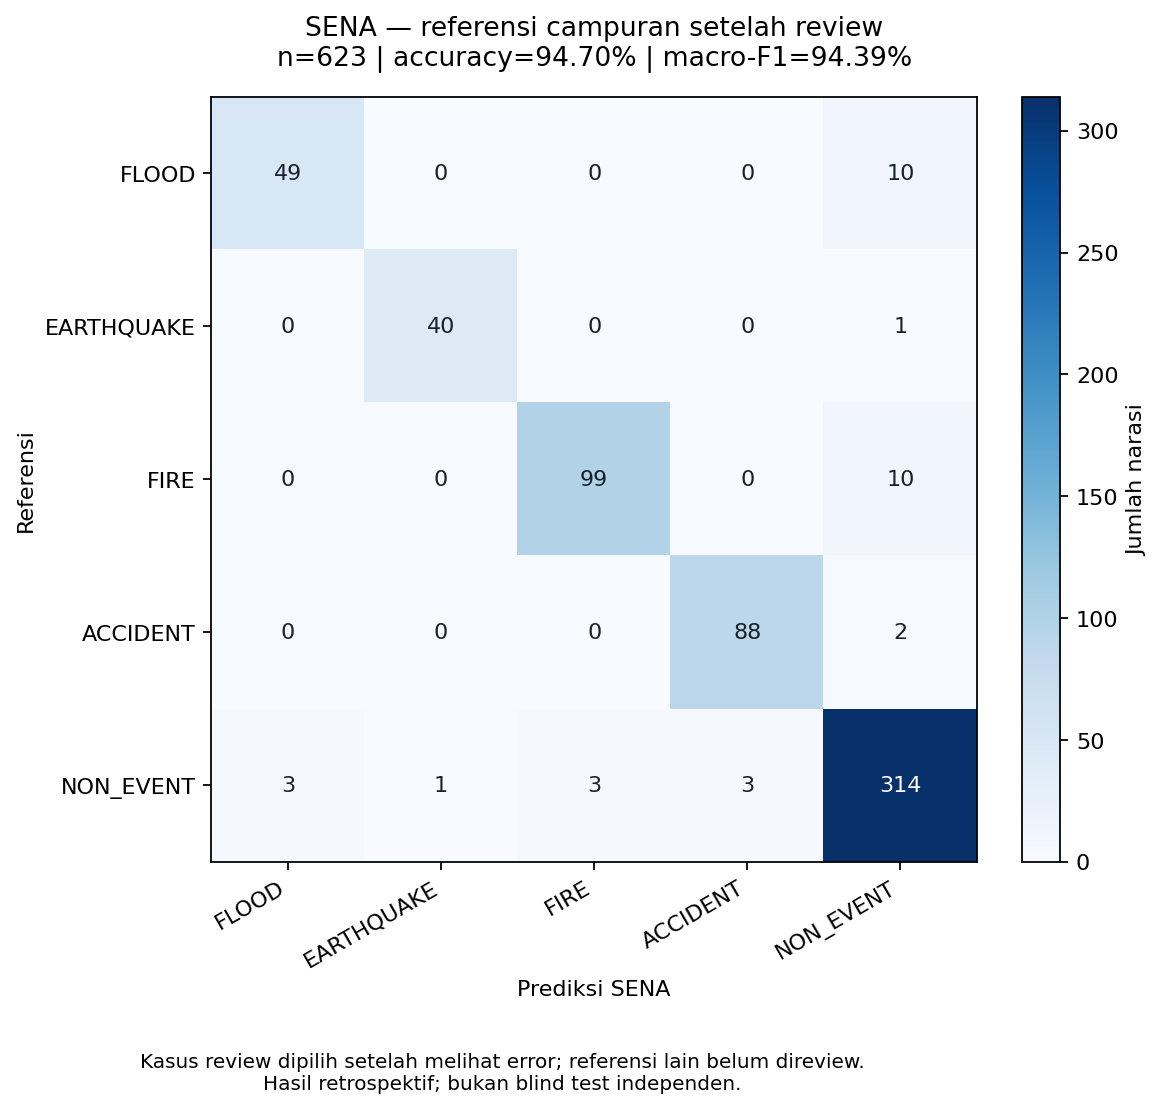

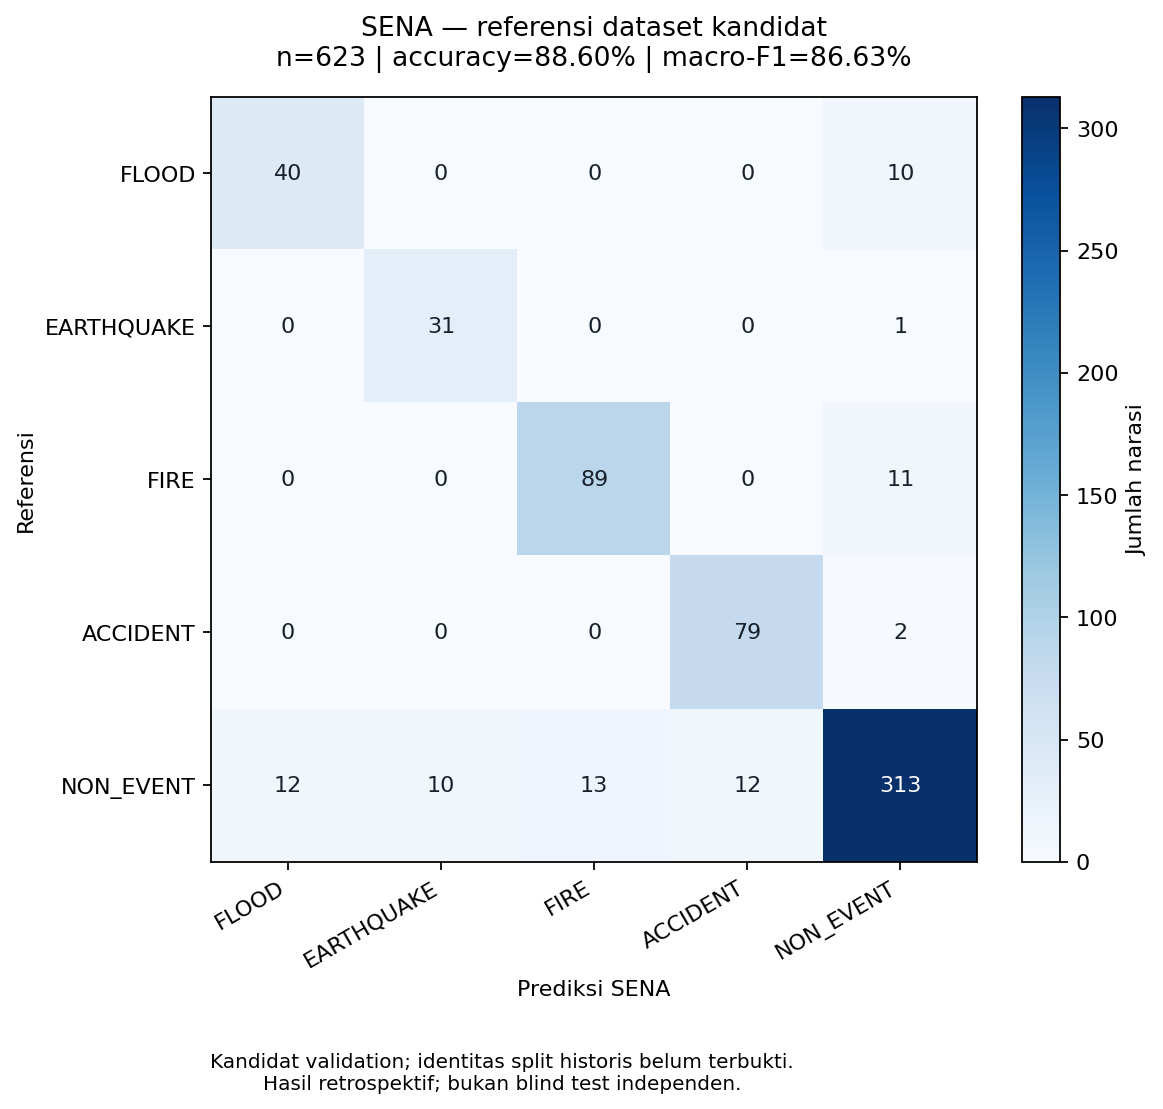

In [22]:
def show_evaluation(folder):
    folder = Path(folder)
    report = json.loads((folder / "review_evaluation.json").read_text(encoding="utf-8"))
    for key, title in [("sena_source_reference", "Referensi dataset kandidat"),
                       ("sena_mixed_reference_retrospective", "Referensi campuran retrospektif")]:
        metrics = report[key]
        print(title, "| n =", metrics["n"],
              "| accuracy =", f"{metrics['accuracy']:.2%}", "| macro-F1 =", f"{metrics['macro_f1']:.2%}")
        print("  label | precision | recall | F1 | support")
        for label, row in metrics["per_class"].items():
            print(" ", label, "|", f"{row['precision']:.4f}", "|", f"{row['recall']:.4f}", "|", f"{row['f1']:.4f}", "|", row["support"])
    fields = report["nara_selected_fields"]
    print("NARA: exact match pada nilai terpilih =", fields["current_exact_matches"], "/", fields["n"])
    print("Sisa nilai NARA yang belum cocok:", fields["n"] - fields["current_exact_matches"])
    print("Mode:", report["mode"], "| inferensi baru pada input run:", report["new_neural_inference_in_input_run"])
    try:
        from IPython.display import Image, display
        for path in sorted((folder / "plots").glob("*.png")):
            display(Image(filename=str(path)))
    except ImportError:
        print("PNG confusion matrix tersedia di:", folder / "plots")

if REPLAY_OK:
    try:
        if importlib.util.find_spec("matplotlib") is None:
            run_step("03a_plot_dependency", [sys.executable, "-m", "pip", "install", "matplotlib"])
        run_step("03b_replay_confusion_matrices", [sys.executable, "slr09_plots.py",
            "--evaluation", str(RESULT_DIR / "review_replay/review_evaluation.json"),
            "--output-dir", str(RESULT_DIR / "review_replay/plots")])
        show_evaluation(RESULT_DIR / "review_replay")
    except Exception as error:
        RUN_STATE["plot_error"] = {"type": type(error).__name__, "message": str(error)}
        print("Gambar gagal, data CSV/JSON tetap tersedia:", error)
    finally:
        save_state()


## Inferensi baru: dependensi Colab

Bagian selanjutnya berjalan jika `RUN_NEURAL_INFERENCE = True`. Mode replay sudah selesai tanpa model. Transformers 5.13.1 mengikuti versi pada inferensi CPU yang berhasil 16 Oktober 2026; versi aktual dicatat lagi saat run. Iterative-stratification 0.1.9 dipakai untuk rekonstruksi kandidat, bukan klaim versi pelatihan historis. PyTorch harus tersedia untuk perangkat CPU/CUDA yang dipilih. Model dimuat dari checkpoint lokal dan tidak dilatih ulang.


In [23]:
if RUN_NEURAL_INFERENCE and REPLAY_OK:
    try:
        if RUNTIME_DEVICE not in {"cpu", "cuda"}:
            raise ValueError("RUNTIME_DEVICE harus cpu atau cuda")
        if CPU_THREADS is not None and (type(CPU_THREADS) is not int or CPU_THREADS < 1):
            raise ValueError("CPU_THREADS harus None atau integer positif")
        if importlib.util.find_spec("torch") is None:
            raise RuntimeError("PyTorch belum tersedia; gunakan environment dengan build CPU/CUDA yang sesuai.")
        requirements = [line.strip() for line in EMBEDDED_FILES["requirements-runtime.txt"].splitlines()
                        if line.strip() and not line.lstrip().startswith("#")]
        setup = subprocess.run(
            [sys.executable, "-m", "pip", "install", "--upgrade-strategy", "only-if-needed", *requirements],
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        )
        (RESULT_DIR / "dependency_setup.log").write_text(setup.stdout, encoding="utf-8")
        if setup.returncode:
            raise RuntimeError("Instalasi dependency gagal; lihat dependency_setup.log.")
        SETUP_OK = True
        RUN_STATE["status"] = "DEPENDENCIES_READY"
        print("Setup dependency selesai. Versi aktual dicatat lagi saat model dijalankan.")
    except Exception as error:
        RUN_STATE["status"] = "DEPENDENCY_SETUP_FAILED"
        RUN_STATE["error"] = {"type": type(error).__name__, "message": str(error)}
        print("SETUP GAGAL:", error, "Lanjutkan ke cell unduh hasil untuk mengambil log.")
    finally:
        save_state()

else:
    print("Setup neural dilewati. Untuk inferensi baru, set RUN_NEURAL_INFERENCE = True dan Run All.")


Setup neural dilewati. Untuk inferensi baru, set RUN_NEURAL_INFERENCE = True dan Run All.


## Hubungkan Google Drive dan salin aset

1. Buat folder **SILAR_SLR09** di **My Drive / Drive Saya** atau gunakan folder Anda sendiri.
2. Upload tiga ZIP asli berikut ke folder tersebut, dengan nama tetap sama:
   - `SILAR_SENA_v1.zip`
   - `SILAR_NARA_v1.zip`
   - `Semantic Role Labeling Datasets for Crisis Event.zip`
3. Pastikan `DRIVE_FOLDER` pada cell konfigurasi menunjuk folder itu. Contoh yang diberikan adalah folder yang perlu Anda buat, bukan asumsi tentang isi Drive Anda.
4. Jalankan cell berikut, pilih akun Drive yang menyimpan aset dan selesaikan izin koneksi yang ditampilkan Colab.

ZIP disalin ke cache lokal Colab lalu diperiksa hash-nya. Bobot diekstrak dan dibaca dari penyimpanan lokal Colab. Cache yang sudah cocok dipakai ulang pada runtime yang sama. Reset VM menghapus cache lokal; sumber di Drive tetap tersedia untuk disalin lagi. Tidak ada `files.upload()` pada alur ini. Isi Drive hanya dibaca, tanpa menghapus atau mengganti sumber.

Referensi: [Google Colab FAQ](https://research.google.com/colaboratory/faq.html), bagian operasi Drive dan saran menyalin arsip ke VM sebelum ekstraksi.


In [24]:
ASSET_NAMES = ["SILAR_SENA_v1.zip", "SILAR_NARA_v1.zip",
               "Semantic Role Labeling Datasets for Crisis Event.zip"]
INPUT_FILES = {name: INPUT_DIRECTORY / name for name in ASSET_NAMES}
if RUN_NEURAL_INFERENCE and SETUP_OK:
    try:
        from google.colab import drive
        drive.mount(str(DRIVE_MOUNT_POINT))
        if not DRIVE_FOLDER.is_dir():
            raise FileNotFoundError("Folder Drive tidak ditemukan. Isi DRIVE_FOLDER sesuai folder Anda: " + str(DRIVE_FOLDER))
        missing = [name for name in ASSET_NAMES if not (DRIVE_FOLDER / name).is_file()]
        if missing:
            raise FileNotFoundError("ZIP belum tersedia di folder Drive: " + ", ".join(missing))
        lock = json.loads((CODE_DIR / "asset_lock.json").read_text(encoding="utf-8"))
        expected_hashes = {
            ASSET_NAMES[0]: lock["models"]["sena"]["archive_sha256"],
            ASSET_NAMES[1]: lock["models"]["nara"]["archive_sha256"],
            ASSET_NAMES[2]: lock["dataset"]["archive_sha256"],
        }
        INPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)
        copy_evidence = []
        for name in ASSET_NAMES:
            source = DRIVE_FOLDER / name
            target = INPUT_FILES[name]
            expected_hash = expected_hashes[name]
            cached_hash = None
            if target.is_symlink():
                raise ValueError("Target cache tidak boleh symlink: " + name)
            if target.is_file():
                digest = hashlib.sha256()
                with target.open("rb") as cached:
                    for block in iter(lambda: cached.read(1024 * 1024), b""):
                        digest.update(block)
                cached_hash = digest.hexdigest()
            if cached_hash == expected_hash:
                print("Cache lokal valid, dipakai ulang:", name, flush=True)
                copy_evidence.append({"file": name, "status": "REUSED_VERIFIED_LOCAL_CACHE", "sha256": cached_hash})
                continue
            temporary = target.with_name(target.name + "." + RUN_ID + ".part")
            digest = hashlib.sha256()
            copied = 0
            next_update = 64 * 1024 * 1024
            print("Menyalin Drive ke Colab:", name, flush=True)
            try:
                with source.open("rb") as incoming, temporary.open("xb") as outgoing:
                    for block in iter(lambda: incoming.read(1024 * 1024), b""):
                        outgoing.write(block)
                        digest.update(block)
                        copied += len(block)
                        if copied >= next_update:
                            print("  Tersalin:", round(copied / 1024**2, 1), "MiB", flush=True)
                            next_update += 64 * 1024 * 1024
                actual_hash = digest.hexdigest()
                if actual_hash != expected_hash:
                    raise ValueError("Hash ZIP berbeda dari aset yang diaudit: " + name)
                temporary.replace(target)
                copy_evidence.append({"file": name, "status": "COPIED_AND_HASH_VERIFIED", "bytes": copied, "sha256": actual_hash})
                print("  Selesai dan hash cocok:", name, flush=True)
            finally:
                temporary.unlink(missing_ok=True)
        (RESULT_DIR / "drive_input_evidence.json").write_text(
            json.dumps({"input_source": "GOOGLE_DRIVE_COPY_TO_LOCAL_CACHE", "files": copy_evidence},
                       ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
        INPUT_OK = True
        RUN_STATE["status"] = "INPUTS_READY"
        print("Tiga ZIP siap pada penyimpanan lokal Colab. Lanjutkan ke cell eksekusi.")
    except Exception as error:
        RUN_STATE["status"] = "INPUT_PREPARATION_FAILED"
        RUN_STATE["error"] = {"type": type(error).__name__, "message": str(error)}
        print("INPUT GAGAL:", error, "Periksa DRIVE_FOLDER atau lanjutkan ke cell unduh hasil untuk mengambil log.")
    finally:
        save_state()
else:
    print("Koneksi Drive dilewati; periksa mode dan status setup neural.")


Koneksi Drive dilewati; periksa mode dan status setup neural.


## Inferensi SENA/NARA dan evaluasi baru

Urutannya: verifikasi aset → 12 diagnostik → rekonstruksi kandidat validation → inferensi SENA → analisis cutoff → evaluasi dengan referensi final → gambar confusion matrix. Run berhenti jika ada kegagalan, termasuk bila himpunan kandidat berbeda dari data yang direview.

Hasil mode `fresh` berbeda dari replay karena jaringan neural benar-benar dijalankan. Dataset test dan blind test tidak dipakai untuk memilih threshold. Threshold produksi tetap `null`; confidence di atas kandidat cutoff tidak melewati Human Verification. Belum ada gold lengkap NARA untuk menghitung mutu keseluruhan tujuh field A4.22.


In [25]:
if RUN_NEURAL_INFERENCE and SETUP_OK and INPUT_OK:
    common = ["--device", RUNTIME_DEVICE, "--environment-label", "NOTEBOOK_" + RUNTIME_DEVICE.upper()]
    if CPU_THREADS is not None:
        common += ["--cpu-threads", str(CPU_THREADS)]
    split_dir = RESULT_DIR / "candidate_split"
    smoke_dir = RESULT_DIR / "smoke"
    validation_dir = RESULT_DIR / "sena_validation"
    analysis_dir = RESULT_DIR / "threshold_analysis"
    commands = [
        ("04_verify_extract_assets", [sys.executable, "slr09_runtime.py", "extract",
            "--sena-zip", str(INPUT_FILES[ASSET_NAMES[0]]), "--nara-zip", str(INPUT_FILES[ASSET_NAMES[1]]),
            "--output-dir", str(ASSET_DIR)]),
        ("05_sena_nara_smoke", [sys.executable, "slr09_runtime.py", "smoke",
            "--sena-dir", str(ASSET_DIR / "sena"), "--nara-dir", str(ASSET_DIR / "nara"),
            "--input", str(CODE_DIR / "smoke_cases.jsonl"), "--output-dir", str(smoke_dir), *common]),
        ("06_reconstruct_candidate_split", [sys.executable, "slr09_calibration.py", "prepare",
            "--dataset-zip", str(INPUT_FILES[ASSET_NAMES[2]]), "--output-dir", str(split_dir)]),
        ("07_sena_candidate_validation", [sys.executable, "slr09_runtime.py", "sena",
            "--sena-dir", str(ASSET_DIR / "sena"), "--input", str(split_dir / "candidate_validation.jsonl"),
            "--output-dir", str(validation_dir), *common]),
        ("08_threshold_analysis", [sys.executable, "slr09_calibration.py", "summarize",
            "--input", str(split_dir / "candidate_validation.jsonl"),
            "--predictions", str(validation_dir / "predictions.jsonl"),
            "--run-summary", str(validation_dir / "run_summary.json"),
            "--split-manifest", str(split_dir / "split_manifest.json"), "--output-dir", str(analysis_dir)]),
        ("09_fresh_review_evaluation", [sys.executable, "slr09_review_evaluation.py", "--mode", "fresh",
            "--references", str(CODE_DIR / "reviewed_references.json"),
            "--smoke-input", str(CODE_DIR / "smoke_cases.jsonl"), "--smoke-predictions", str(smoke_dir / "predictions.jsonl"),
            "--sena-input", str(split_dir / "candidate_validation.jsonl"),
            "--sena-predictions", str(validation_dir / "predictions.jsonl"),
            "--smoke-run-summary", str(smoke_dir / "run_summary.json"),
            "--sena-run-summary", str(validation_dir / "run_summary.json"),
            "--output-dir", str(RESULT_DIR / "review_fresh")]),
        ("10_fresh_confusion_matrices", [sys.executable, "slr09_plots.py",
            "--evaluation", str(RESULT_DIR / "review_fresh/review_evaluation.json"),
            "--output-dir", str(RESULT_DIR / "review_fresh/plots")]),
    ]
    RUN_STATE["status"] = "RUNNING_NEURAL_INFERENCE"
    save_state()
    try:
        for name, command in commands:
            run_step(name, command, offline_models=True)
        RUN_STATE["status"] = "NEURAL_RUN_SUCCEEDED_EXPLORATORY_ANALYSIS_ONLY"
        show_evaluation(RESULT_DIR / "review_fresh")
    except Exception as error:
        RUN_STATE["status"] = "NEURAL_RUN_FAILED"
        RUN_STATE["error"] = {"type": type(error).__name__, "message": str(error)}
        print("EKSEKUSI GAGAL:", error, "Lanjutkan ke cell ekspor.")
    finally:
        actual_summaries = []
        for path in [smoke_dir / "run_summary.json", validation_dir / "run_summary.json"]:
            if path.is_file():
                actual_summaries.append(json.loads(path.read_text(encoding="utf-8")))
        RUN_STATE["new_neural_inference_executed"] = any(
            item.get("model_inference_executed") is True for item in actual_summaries)
        save_state()
elif not RUN_NEURAL_INFERENCE:
    print("Mode replay selesai. Inferensi neural baru belum dijalankan pada run ini.")
else:
    print("Inferensi neural dilewati karena setup atau input belum siap. Status:", RUN_STATE["status"])


Mode replay selesai. Inferensi neural baru belum dijalankan pada run ini.


## Ekspor bukti

Jalankan cell ini juga jika setup atau inferensi gagal. ZIP memuat kode lengkap yang digunakan, hash, data baseline untuk replay, log, metrik, CSV, serta gambar yang berhasil dibuat. Model dan dataset ZIP tidak disertakan. Periksa `notebook_run_state.json`: `replay_executed` dan `new_neural_inference_executed` menunjukkan apa yang benar-benar berjalan. Notebook asli pelatihan SENA dan riwayat Fusion/blind disertakan terpisah pada paket penyerahan, bukan dieksekusi di sini.

Jika menjalankan mode neural di Colab, kirim `SLR09_Hasil_Runtime_<run_id>.zip` untuk peninjauan berikutnya. Hasil Colab belum membuktikan kapasitas VM deployment.


In [26]:
zip_path = WORK_ROOT / ("SLR09_Hasil_Runtime_" + RUN_ID + ".zip")
RUN_STATE["result_archive_name"] = zip_path.name
save_state()
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(RESULT_DIR.rglob("*")):
        if path.is_file():
            archive.write(path, "results/" + path.relative_to(RESULT_DIR).as_posix())
    for path in sorted(CODE_DIR.iterdir()):
        if path.is_file():
            archive.write(path, "executed_code/" + path.name)
    for path in sorted(BASELINE_DIR.iterdir()):
        if path.is_file():
            archive.write(path, "baseline_evidence/" + path.name)
    evidence = ASSET_DIR / "extraction_evidence.json"
    if evidence.is_file():
        archive.write(evidence, "results/extraction_evidence.json")
print("Status:", RUN_STATE["status"])
print("Hasil:", zip_path.name)
analysis_path = RESULT_DIR / "threshold_analysis/threshold_analysis.json"
if analysis_path.is_file():
    analysis = json.loads(analysis_path.read_text())
    print("Status analisis:", analysis["status"])
    print("Jumlah kandidat validation:", analysis["records"])
    print("Threshold produksi:", analysis["production_confidence_threshold"])
print("Replay dijalankan:", RUN_STATE["replay_executed"])
print("Inferensi neural baru:", RUN_STATE["new_neural_inference_executed"])
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Di luar Colab, ambil file:", zip_path)


Status: REPLAY_SUCCEEDED
Hasil: SLR09_Hasil_Runtime_20261017T120856_319468Z.zip
Replay dijalankan: True
Inferensi neural baru: False
Di luar Colab, ambil file: /workspace/scratch/6258ae7d1a8b/tmp/slr09_postproc/notebook_execution/slr09_runtime/20261017T120856_319468Z/SLR09_Hasil_Runtime_20261017T120856_319468Z.zip
